[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QHT_CertifiedRobustness_Weber2021.ipynb)

# Optimal provable robustness of a quantum classifier through quantum hypothesis testing: Weber et al. (2021) step by step

**Paper.** Maurice Weber, Nana Liu, Bo Li, Ce Zhang and Zhikuan Zhao, *Optimal provable robustness of quantum classification via
quantum hypothesis testing*, npj Quantum Information **7**, 76 (2021), DOI [10.1038/s41534-021-00410-5](https://doi.org/10.1038/s41534-021-00410-5).

**What this notebook does.** The paper is a theory paper: it proves that the answer of a quantum classifier cannot change for
any perturbed input state that stays within a certain fidelity (or trace distance, or noise strength) of the clean state, and that
this radius is the best one can say when only the class probabilities are known. There is no dataset, no training run and no
accuracy table to copy. What *can* be checked are the numbers and formulas the paper prints (the 0.44 of Eq. 31, the 0.93 of
Eq. 33, the orderings of Figs. 2 and 5, the noise bounds of Fig. 4) and the claims "sufficient", "necessary" and "tight". This
notebook therefore

1. implements the quantum-hypothesis-testing (QHT) machinery from scratch (Neyman-Pearson problem as a semidefinite programme
   solved through its Lagrange dual, Helstrom operators, all closed forms of the paper) and tests it against independent solvers;
2. redoes the paper's single-qubit example and re-draws Figs. 2-5, with a verdict for every printed number;
3. tests Theorem 1 (soundness), Theorem 2 (tightness: the worst-case classifier is built explicitly), Lemma 1 and Theorem 3 on
   thousands of random states and random multi-class measurements;
4. adds what a security reader needs, an experiment on **real data**: a trained 6-qubit classifier for two handwritten digits
   (amplitude encoding of real images), its certified accuracy (Protocol 1 with real Aer shots, Protocol 2 with real noise
   channels), a classical randomised-smoothing certificate on exactly the same inputs, and attacks: the exact optimal adversary
   (Lagrange dual) and a practical gradient attack, to see how close the certificate comes to the truth.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (config cell) gives a reduced run; `False`
uses the full budgets listed at the end of the config cell. No GPU, no account, no download: the digit images are bundled with
scikit-learn. A session restart may be needed after the install cell.

**What you get at the end.** A table with one verdict per claim of the paper (reproduced / not reached / cannot be checked), the
drawn circuits, the re-drawn figures, certified-versus-attacked accuracy curves for the quantum classifier and its classical
counterpart, and a critical reading that points out where the printed text does not match the mathematics (the example classifier) and
where a claim of tightness is only partly true (noise-model bounds, trace distance for mixed adversaries).

## The paper in one page

* **Problem.** A quantum classifier maps a state `sigma` through a channel `E` and a measurement `{Pi_k}`; the score is
  `y_k(sigma) = Tr[Pi_k E(sigma)]` and the prediction is the most likely class. Input perturbations (hardware noise or an
  adversary who applies an arbitrary quantum operation) can change the prediction. *Provable robustness* means: for every
  state `rho` that satisfies a condition `R`, `A(rho) = A(sigma)`.
* **Idea.** Seen from the Heisenberg picture, `1 - Lambda_kA` is a hypothesis test between the clean state `sigma` (null) and
  the perturbed state `rho` (alternative). The classifier can never beat the *optimal* test, and the optimal test is the
  Helstrom operator of the Neyman-Pearson problem
  `beta*_{alpha0}(sigma, rho) = min Tr[rho (1 - M)]  s.t.  Tr[sigma M] <= alpha0,  0 <= M <= 1`.
* **Theorem 1.** If `y_kA(sigma) >= pA > pB >= max_{k != kA} y_k(sigma)` then `A(rho) = A(sigma)` for every `rho` with
  `beta*_{1-pA}(sigma, rho) + beta*_{pB}(sigma, rho) > 1` (for `pB = 1 - pA`: `beta*_{1-pA} > 1/2`).
* **Theorem 2 (tightness).** For `pA + pB = 1` the condition is also necessary: if it fails, an explicit classifier built from the
  Helstrom operator has the same class probabilities on `sigma` and still classifies `rho` differently.
* **Closed forms.** Pure states (Lemma 1, Eq. 12/14): robust iff `F(rho, sigma) > (1 + sqrt(g(pA, pB)))/2`, with
  `g = 1 - pB - pA(1 - 2 pB) + 2 sqrt(pA pB (1 - pA)(1 - pB))`; equivalent forms for the Bures distance and the trace distance
  (Eq. 15/16); mixed states (Theorem 3): the same fidelity condition, still tight; trace distance for mixed adversaries
  (Corollary 1, Eq. 21) is weaker than the Holder-duality bound `T < (pA - pB)/2` (Lemma 2, independently found by Guan et al.).
* **Protocols.** Protocol 1 (estimate `pA` with Hoeffding's inequality from `N` executions and return the certified fidelity),
  Protocol 2 (certify that a noisy input was classified like the clean one without seeing the clean one), tight noise-parameter
  bounds for phase damping (Eq. 38) and amplitude damping (Eq. 40), and *depolarisation smoothing*, a quantum analogue of
  randomised smoothing, with the single-qubit radius of Eq. 43 compared with the Holder (Eq. 45) and the differential-privacy
  (Eq. 46) bounds.
* **Experiments in the paper.** (i) one single-qubit example: `sigma = |0>`, `rho = cos(theta0/2)|0> + sin(theta0/2) e^{i phi0}|1>`
  with `theta0 = pi/3`, `phi0 = pi/6`, `pA = 0.9` (Eqs. 23-34, Fig. 3: `beta* ~ 0.44`, certified angle `~ 0.93`); (ii) numerical
  plots of formulas (Figs. 2, 4, 5). No dataset, no training, no accuracy.
* **Claims this notebook checks.** Every number and ordering above, plus soundness, tightness, equivalence of the closed forms and
  the protocols, and (our extension) the behaviour of the certificate on a trained classifier against real attacks.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | none: analytic single-qubit states (Eqs. 23, 24) | Part A: exactly those states. Part B (our extension, `# CHOICE`): the 365 real 8x8 images of the digits 3 and 5 from the UCI optical-digits set bundled with scikit-learn |
| Quantum classifier | any CPTP map + POVM ("model agnostic"); toy POVM `{Pi_{theta,phi}, 1 - Pi}` with `theta = 0.644`, `phi = pi/2` | Part A: that POVM as a one-qubit circuit. Part B (`# CHOICE`): amplitude encoding of the 64 pixels on 6 qubits, `RealAmplitudes(reps=3)` (24 parameters), qubit 0 is measured |
| Training | none | L-BFGS-B on the exact simulator, cross-entropy, adjoint gradient, restarts chosen on the validation loss (`# CHOICE`) |
| SDP for `beta*` | stated as an SDP, solver not named | Lagrange dual `max_t 1 - t alpha0 - Tr(rho - t sigma)_+` by bisection, primal Helstrom operator `M_t` built explicitly; checked against closed forms and an independent SLSQP solver |
| Eq. (21), `delta` | printed `delta = [(1 - g)/2]^(1/2)` | both that and `delta = r_Q` are tested (`# CHOICE`) |
| Eq. (43) | printed, partly unreadable in the PDF text | reconstructed from the printed symbols; the first branch is re-derived independently, the second branch and the switch point match the exact SDP |
| Hoeffding confidence / shots | `alpha`, `N` not given | `alpha = 0.001`, `N = 2000` executions (`# CHOICE`) |
| Adversary | "arbitrary quantum operation" | exact optimal adversary via the dual (any pure or mixed state at fidelity >= 1 - eps) and a majorise-minimise gradient attack on pure states |
| Classical baseline | randomised smoothing of Cohen et al. is the motivation, not a baseline | logistic regression trained with Gaussian noise on the *same* 64-dimensional unit vectors, Clopper-Pearson certification (`alpha = 0.001`), noise level chosen on the validation split; the l2 radius is converted to a fidelity through `F = (1 - R^2/2)^2` |
| Tolerance for "reproduced" | n/a | 0.02 absolute for printed numbers, exact (1e-6) for closed-form identities, zero violations for "guaranteed" statements |

In [1]:
# Pinned installs (tested versions). Colab already ships numpy, pandas, scipy, scikit-learn and matplotlib.
# The cell does nothing when the tested Qiskit versions are already present (e.g. a local environment).
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
def _qiskit_ok():
    try:
        import qiskit, qiskit_aer, pylatexenc
        return qiskit.__version__ == "2.5.2" and qiskit_aer.__version__ == "0.17.2"
    except Exception:
        return False
if IN_COLAB or not _qiskit_ok():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"], check=False)
    print("installed qiskit 2.5.2, qiskit-aer 0.17.2, pylatexenc. If an import below fails, restart the session (Runtime -> Restart) and run all cells again.")
else:
    print("tested versions already installed: nothing to do")

tested versions already installed: nothing to do


In [2]:
# ============================ CONFIGURATION (every tunable constant lives here) ============================
FAST_MODE = False            # True: small budgets, a few minutes.  False: the full budgets documented below.
SEED = 42                   # one seed for everything (numpy, scikit-learn, Qiskit-Aer, the random states of the checks)

# --- real data (Part B) ---
DATA_SOURCE = "sklearn"     # CHOICE: the UCI "optical recognition of handwritten digits" set bundled with scikit-learn
                            # (no download, no account); "upload" is not needed because nothing is gated.
DATA_DIR = "qc329_cache"    # kept for convention; this notebook downloads nothing
DIGIT_PAIR = (3, 5)         # CHOICE: binary task "digit 3 versus digit 5" (8x8 images, 64 amplitudes = 6 qubits)
TEST_SIZE = 0.30            # stratified train/test split
VAL_SIZE = 0.25             # part of the training split used for model selection (validation); the test set is never used for fitting

# --- the quantum classifier (Part B) ---
N_QUBITS = 6                # 2**6 = 64 = number of pixels: amplitude encoding of the 8x8 image
REPS = 3                    # repetitions of the RealAmplitudes ansatz (24 trainable parameters)
TRAIN_RESTARTS = 3 if FAST_MODE else 6      # random restarts of the optimiser
TRAIN_MAXITER = 150 if FAST_MODE else 400   # L-BFGS-B iterations per restart
SEEDS_ACC = [42, 43, 44] if FAST_MODE else [42, 43, 44, 45, 46]   # seeds for the "mean +- std" accuracy table

# --- checks of the theory (Parts A, 1-6) ---
N_RANDOM_TRIALS = 100 if FAST_MODE else 400      # random (sigma, classifier) pairs for Theorem 1 (9 perturbation strengths each) and pairs for Theorem 2
N_MIXED_DIRS = 30 if FAST_MODE else 80           # random directions per (dimension, pA) for the mixed-state trace-distance radius
GRID = 41 if FAST_MODE else 81                   # grid resolution for the Fig. 2 / Fig. 4 / Fig. 5 re-draws

# --- certification and attacks on the real classifier (Part B) ---
N_CERT = 60 if FAST_MODE else 1000          # number of test states certified/attacked (capped at the test-set size)
EPS_MAX, EPS_STEPS = 0.5, 26   # fidelity budgets eps = 1 - F on a grid from 0 to EPS_MAX
HOEFFDING_ALPHA = 0.001     # failure probability of the Hoeffding bound in the sampling protocols
SHOTS_PROTOCOL = 2000       # circuit executions N in Protocol 1 / Protocol 2
COVERAGE_REPS = 2000 if FAST_MODE else 20000   # repetitions of the Hoeffding coverage experiment
SMOOTH_P = [0.0, 0.1, 0.3, 0.5]             # depolarising smoothing strengths p
SIGMA_RS_GRID = [0.05, 0.10, 0.20, 0.30, 0.40]   # CHOICE: candidate Gaussian noise levels (per coordinate) of the classical randomised-smoothing
                                     # baseline; the one with the best VALIDATION score is used (selected in the certification section)
N_RS_SAMPLES = 1000 if FAST_MODE else 5000  # Monte-Carlo noise draws of the classical smoothed classifier
ATTACK_ITERS = 150 if FAST_MODE else 600    # iterations of the projected-gradient (MM) attack

IBM_TOKEN = ""              # not used: no real hardware is needed for this paper (kept for convention)

# Full-run budgets (FAST_MODE = False): 400 random pairs for Theorem 1/2, 80 mixed-state directions per row, 81-point grids,
# 5 seeds for the accuracy table, 6 optimiser restarts of 400 iterations, 20000 coverage repetitions, 5000 smoothing draws,
# 600 attack iterations; all 110 test states are certified and attacked (FAST_MODE: the first 60).

In [3]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import optimize, stats
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import real_amplitudes, StatePreparation
from qiskit.quantum_info import Statevector, DensityMatrix, Operator, state_fidelity
import qiskit_aer
import qiskit_aer.library                      # registers save_probabilities / save_density_matrix / set_density_matrix on QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import depolarizing_error, amplitude_damping_error, phase_damping_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

rng = np.random.default_rng(SEED)           # one numpy generator for the random checks
np.random.seed(SEED)
EPS_GRID = np.round(np.linspace(0.0, EPS_MAX, EPS_STEPS), 4)
t_notebook_start = time.time()

print("python-level libraries:")
for name, mod in [("numpy", np), ("scipy", scipy), ("scikit-learn", sklearn), ("qiskit", qiskit),
                  ("qiskit-aer", qiskit_aer), ("matplotlib", matplotlib), ("pandas", pd)]:
    print(f"  {name:13s} {mod.__version__}")
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED)

python-level libraries:
  numpy         2.5.4
  scipy         1.18.1
  scikit-learn  1.9.1
  qiskit        2.5.2
  qiskit-aer    0.17.2
  matplotlib    3.11.2
  pandas        3.0.6
FAST_MODE = False | SEED = 42


## Dataset Exploration and Visualisation

**Which data are used where.** The paper itself uses no dataset: its example is made of analytic single-qubit states, which are
drawn on the Bloch sphere in Part A (they are specified by two angles, not observed). The only *observed* data in this notebook
are those of Part B, the experiment we add so that the certificates can be tried on a real task: the **UCI "optical
recognition of handwritten digits"** images (1797 real 8x8 grey-level scans of the digits 0-9, shipped with scikit-learn, so no
download or account is needed). We keep the digits **3 and 5** (365 images; `# CHOICE`, a pair that is easy to confuse at
8x8 resolution) and encode every image `x` as the 6-qubit state `|x> = x / ||x||` (amplitude encoding, 64 amplitudes). The
encoding has no fitted parameter, so nothing can leak from the test set into it; the stratified train/validation/test split is
done once with `random_state = SEED`. The two cells below print the shape, the feature names and the original labels with their
counts, plot the real class distribution, show real examples, and then draw every real observation as a point coloured by its
ground-truth digit in the plane of the first two PCA coordinates (PCA fitted on the training split only). Because the model
uses amplitude encoding there is no angle encoding and therefore no `[0, pi]` scaling to draw; the geometry that matters for
the certificates is the fidelity between encoded states, which is the squared cosine similarity of the pixel vectors.

full data set      : X shape (1797, 64) | y shape (1797,)
feature names      : ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5'] ... (64 pixels, grey level 0-16)
original labels    : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
class counts (all) : {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}



selected task      : digit 3 (class 0) vs digit 5 (class 1), 365 real observations
encoded state matrix: (365, 64) (rows: unit vectors = quantum states of 6 qubits)
train / validation / test sizes: 191 64 110
class counts train: {0: 128, 1: 127} | test: {0: 55, 1: 55} (0 = digit 3, 1 = digit 5)


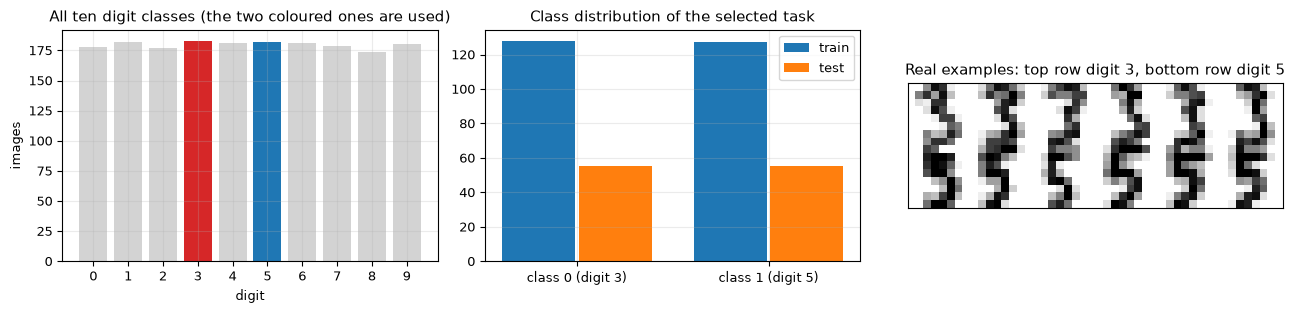

In [4]:
# ---- real data: UCI optical handwritten digits (1797 real 8x8 scans, bundled with scikit-learn) ----
digits = load_digits()
X_all, y_all = digits.data, digits.target
print("full data set      : X shape", X_all.shape, "| y shape", y_all.shape)
print("feature names      :", [f"pixel_{i // 8}_{i % 8}" for i in range(64)][:6], "... (64 pixels, grey level 0-16)")
print("original labels    :", sorted(np.unique(y_all).tolist()))
print("class counts (all) :", {int(k): int(v) for k, v in zip(*np.unique(y_all, return_counts=True))})

# CHOICE: binary task DIGIT_PAIR; class 0 = first digit, class 1 = second digit
mask = np.isin(y_all, DIGIT_PAIR)
X_raw = X_all[mask] / 16.0                                    # grey levels in [0, 1]
y_dig = y_all[mask]                                           # original labels (3 or 5)
y = (y_dig == DIGIT_PAIR[1]).astype(int)
# Amplitude encoding: the state is |x> = x / ||x||  (fixed, no parameters are fitted, so no train/test leakage is possible)
X_amp = X_raw / np.linalg.norm(X_raw, axis=1, keepdims=True)
idx_all = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx_all, test_size=TEST_SIZE, stratify=y, random_state=SEED)
idx_tr2, idx_val = train_test_split(idx_tr, test_size=VAL_SIZE, stratify=y[idx_tr], random_state=SEED)
Xtr, Xte, ytr, yte = X_amp[idx_tr], X_amp[idx_te], y[idx_tr], y[idx_te]
print(f"\nselected task      : digit {DIGIT_PAIR[0]} (class 0) vs digit {DIGIT_PAIR[1]} (class 1), {len(y)} real observations")
print("encoded state matrix:", X_amp.shape, "(rows: unit vectors = quantum states of 6 qubits)")
print("train / validation / test sizes:", len(idx_tr2), len(idx_val), len(idx_te))
print("class counts train:", {int(k): int(v) for k, v in zip(*np.unique(ytr, return_counts=True))},
      "| test:", {int(k): int(v) for k, v in zip(*np.unique(yte, return_counts=True))}, "(0 = digit %d, 1 = digit %d)" % DIGIT_PAIR)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
vals, cnt = np.unique(y_all, return_counts=True)
cols = ["tab:red" if v == DIGIT_PAIR[0] else "tab:blue" if v == DIGIT_PAIR[1] else "lightgray" for v in vals]
ax[0].bar(vals, cnt, color=cols); ax[0].set_xticks(vals)
ax[0].set_title("All ten digit classes (the two coloured ones are used)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
for k, (nm, yy) in enumerate([("train", ytr), ("test", yte)]):
    c = np.bincount(yy, minlength=2)
    ax[1].bar(np.arange(2) + 0.4 * k, c, width=0.38, label=nm, color=["tab:red", "tab:blue"][k] if False else None)
ax[1].set_xticks([0.2, 1.2]); ax[1].set_xticklabels([f"class 0 (digit {DIGIT_PAIR[0]})", f"class 1 (digit {DIGIT_PAIR[1]})"])
ax[1].set_title("Class distribution of the selected task"); ax[1].legend()
grid = np.zeros((2 * 8, 8 * 6))
for r_, dgt in enumerate(DIGIT_PAIR):
    imgs = X_all[y_all == dgt][:6].reshape(-1, 8, 8)
    for j in range(6):
        grid[r_ * 8:(r_ + 1) * 8, j * 8:(j + 1) * 8] = imgs[j]
ax[2].imshow(grid, cmap="gray_r"); ax[2].set_xticks([]); ax[2].set_yticks([]); ax[2].grid(False)
ax[2].set_title(f"Real examples: top row digit {DIGIT_PAIR[0]}, bottom row digit {DIGIT_PAIR[1]}")
plt.tight_layout(); plt.show()

explained variance of the two PCA axes (fitted on train): [0.328 0.123]


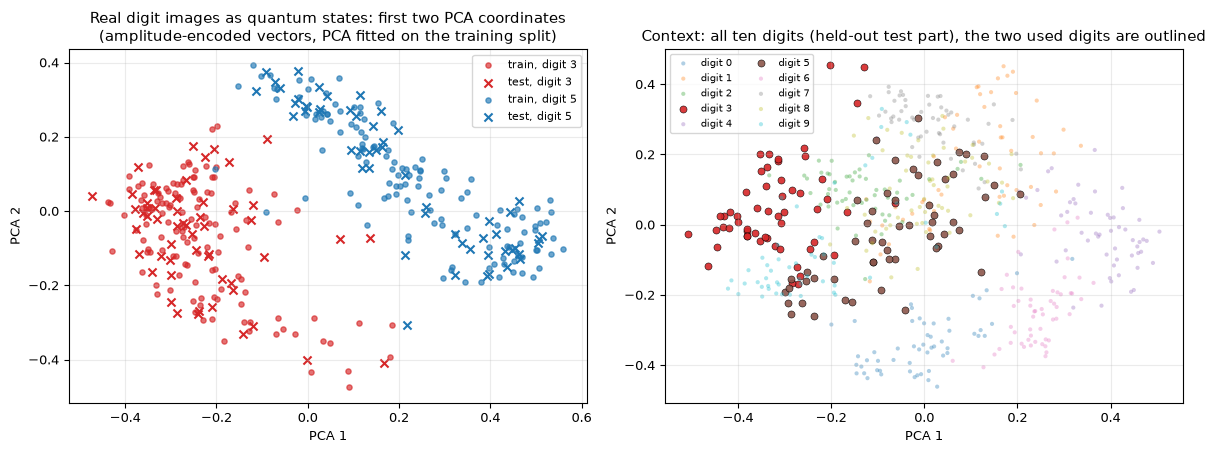

The model uses AMPLITUDE encoding (the 64 normalised pixels are the 64 amplitudes of a 6-qubit state), so there is no angle
scaling to [0, pi]; the scatter above is the geometry the quantum states live in (fidelity = squared cosine similarity).
mean cosine similarity: within digit 3 0.833, within digit 5 0.806, between 0.698  (fidelity between classes about 0.49)


In [5]:
# ---- 2-D scatter of the REAL observations coloured by their ground-truth digit ----
pca2 = PCA(n_components=2, random_state=SEED).fit(Xtr)          # fitted on the TRAINING split only
Ztr, Zte = pca2.transform(Xtr), pca2.transform(Xte)
print("explained variance of the two PCA axes (fitted on train):", pca2.explained_variance_ratio_.round(3))

# context panel: all ten digits, PCA fitted on the training part of the full 10-class data
Xall_amp = X_all / 16.0
Xall_amp = Xall_amp / np.linalg.norm(Xall_amp, axis=1, keepdims=True)
ia_tr, ia_te = train_test_split(np.arange(len(y_all)), test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
pca_ctx = PCA(n_components=2, random_state=SEED).fit(Xall_amp[ia_tr])
Zc = pca_ctx.transform(Xall_amp[ia_te])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, colr in [(0, "tab:red"), (1, "tab:blue")]:
    ax[0].scatter(*Ztr[ytr == lab].T, s=14, c=colr, alpha=0.65, label=f"train, digit {DIGIT_PAIR[lab]}")
    ax[0].scatter(*Zte[yte == lab].T, s=34, c=colr, marker="x", label=f"test, digit {DIGIT_PAIR[lab]}")
ax[0].set_title("Real digit images as quantum states: first two PCA coordinates\n(amplitude-encoded vectors, PCA fitted on the training split)")
ax[0].set_xlabel("PCA 1"); ax[0].set_ylabel("PCA 2"); ax[0].legend(fontsize=8)
cm = plt.get_cmap("tab10")
for dgt in range(10):
    m = y_all[ia_te] == dgt
    big = dgt in DIGIT_PAIR
    ax[1].scatter(*Zc[m].T, s=26 if big else 9, color=cm(dgt), alpha=0.9 if big else 0.35, label=f"digit {dgt}",
                  edgecolor="k" if big else "none", linewidth=0.4)
ax[1].set_title("Context: all ten digits (held-out test part), the two used digits are outlined")
ax[1].set_xlabel("PCA 1"); ax[1].set_ylabel("PCA 2"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()
print("The model uses AMPLITUDE encoding (the 64 normalised pixels are the 64 amplitudes of a 6-qubit state), so there is no angle")
print("scaling to [0, pi]; the scatter above is the geometry the quantum states live in (fidelity = squared cosine similarity).")
c_in = (Xtr[ytr == 0] @ Xtr[ytr == 0].T).mean(), (Xtr[ytr == 1] @ Xtr[ytr == 1].T).mean(), (Xtr[ytr == 0] @ Xtr[ytr == 1].T).mean()
print(f"mean cosine similarity: within digit {DIGIT_PAIR[0]} {c_in[0]:.3f}, within digit {DIGIT_PAIR[1]} {c_in[1]:.3f}, between {c_in[2]:.3f}"
      f"  (fidelity between classes about {c_in[2] ** 2:.2f})")

## 1. The QHT toolbox: every formula of the paper as a tested function

Everything below rests on one small piece of mathematics, the **Neyman-Pearson problem** between two density matrices. For a
type-I error budget `alpha0` we need `beta*_{alpha0}(sigma, rho)`, the smallest type-II error that any measurement `0 <= M <= 1`
can reach. It is a semidefinite programme with a one-dimensional Lagrange dual,
`beta* = max_{t >= 0}  1 - t alpha0 - Tr[(rho - t sigma)_+]`  (strong duality holds), and the optimiser is the Helstrom operator
`M_t = P_{t,+} + X_t` of Eq. (4): the projector on the positive eigenspace of `rho - t sigma`, plus a fraction of the null space
when the budget `alpha0` has to be met exactly. `t*` is found by bisection (the type-I error of `P_{t,+}` is non-increasing in
`t`); no external SDP solver is needed. The cell below defines this together with the closed forms of the paper (Eqs. 13, 14, 16,
17, 20, 22). The next cell proves that the machinery is right before anything is built on it: closed form versus dual for pure
states, primal Helstrom operator versus dual for mixed states (including `0 <= M <= 1` and `Tr[sigma M] = alpha0`), and, for a
qubit, a brute-force search over 400,000 random tests plus an independent constrained optimiser.

In [6]:
# ---- The QHT toolbox: every formula of the paper as a small, tested function ----
def g_fun(pA, pB):
    """Eq. (13): g(pA, pB) = 1 - pB - pA (1 - 2 pB) + 2 sqrt(pA pB (1 - pA) (1 - pB))."""
    pA, pB = np.asarray(pA, float), np.asarray(pB, float)
    return 1 - pB - pA * (1 - 2 * pB) + 2 * np.sqrt(np.clip(pA * pB * (1 - pA) * (1 - pB), 0, None))

def r_fid(pA, pB=None):
    """Fidelity radius, Eq. (17): robust if F(rho, sigma) > r_F = (1 + sqrt(g)) / 2 (pB = 1 - pA gives Eq. 14)."""
    pB = 1 - np.asarray(pA, float) if pB is None else pB
    return 0.5 * (1 + np.sqrt(g_fun(pA, pB)))

def r_trace_qht_pure(pA, pB=None):
    """Eq. (16), pure states: robust if T(rho, sigma) < [ (1 - sqrt g) / 2 ]^(1/2)   (T^2 = 1 - F for pure states)."""
    return np.sqrt(1 - r_fid(pA, pB))

def r_trace_holder(pA, pB=None):
    """Lemma 2 / Eq. (22): robust if T(rho, sigma) < (pA - pB) / 2."""
    pB = 1 - np.asarray(pA, float) if pB is None else pB
    return (np.asarray(pA, float) - pB) / 2

def r_bures(pA, pB=None):
    """Eq. (20): robust if d_B(rho, sigma) < [ 2 - sqrt(2 (1 + sqrt g)) ]^(1/2)."""
    return np.sqrt(2 - np.sqrt(2 * (1 + np.sqrt(g_fun(pA, 1 - np.asarray(pA, float) if pB is None else pB)))))

def dag(a):
    return a.conj().T

def proj(v):
    v = np.asarray(v, complex).reshape(-1, 1)
    return v @ dag(v)

def trace_distance(a, b):
    return 0.5 * np.abs(np.linalg.eigvalsh(a - b)).sum()

def uhlmann_fidelity(a, b):
    """Uhlmann fidelity F = (Tr sqrt(sqrt(a) b sqrt(a)))^2 (the paper's convention: the squared one)."""
    w, v = np.linalg.eigh(a)
    sa = (v * np.sqrt(np.clip(w, 0, None))) @ dag(v)
    ev = np.linalg.eigvalsh(sa @ b @ sa)
    return float(np.sqrt(np.clip(ev, 0, None)).sum() ** 2)

def _dual_value(t, sigma, rho, alpha0):
    ev = np.linalg.eigvalsh(rho - t * sigma)
    return 1 - t * alpha0 - ev[ev > 0].sum()

def _alpha_plus(t, sigma, rho):
    """alpha(P_{t,+}) = tr[sigma P_{t,+}], P_{t,+} = projector on the positive eigenspace of rho - t sigma."""
    w, v = np.linalg.eigh(rho - t * sigma)
    vp = v[:, w > 1e-13]
    return float(np.real(np.sum(vp.conj() * (sigma @ vp))))

def t_star(sigma, rho, alpha0, iters=40):
    """Optimal Lagrange multiplier t* of the Neyman-Pearson SDP: the value of t at which alpha(P_{t,+}) crosses alpha0.
    alpha(P_{t,+}) is non-increasing in t, so plain bisection on t in [0, 1/alpha0 + 1] works."""
    lo, hi = 0.0, 1.0 / alpha0 + 1.0
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        if _alpha_plus(mid, sigma, rho) > alpha0:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def beta_star(sigma, rho, alpha0):
    """beta*_{alpha0}(sigma, rho) = min tr[rho (1 - M)] s.t. tr[sigma M] <= alpha0, 0 <= M <= 1  (SDP, Eq. 3).
    Lagrange dual (strong duality holds): max_{t>=0}  1 - t alpha0 - tr[(rho - t sigma)_+]."""
    if alpha0 <= 0:
        return float(np.real(np.trace(rho @ (np.eye(len(rho)) - _support_proj(sigma)))))
    if alpha0 >= 1:
        return 0.0
    t = t_star(sigma, rho, alpha0)
    return float(_dual_value(t, sigma, rho, alpha0))

def _support_proj(sigma, tol=1e-12):
    w, v = np.linalg.eigh(sigma)
    vv = v[:, w > tol]
    return vv @ dag(vv)

def helstrom_operator(sigma, rho, alpha0, tol=1e-9):
    """Primal optimiser M_t = P_{t,+} + X_t of Eq. (4) with tr[sigma M] = alpha0 (X_t is a fraction of the null eigenspace)."""
    t = t_star(sigma, rho, alpha0)
    w, v = np.linalg.eigh(rho - t * sigma)
    Pp = v[:, w > tol] @ dag(v[:, w > tol])
    Pz = v[:, np.abs(w) <= tol] @ dag(v[:, np.abs(w) <= tol])
    a_p = float(np.real(np.trace(sigma @ Pp)))
    a_z = float(np.real(np.trace(sigma @ Pz)))
    x = 0.0 if a_z < 1e-12 else float(np.clip((alpha0 - a_p) / a_z, 0, 1))
    return Pp + x * Pz, t

def beta_pure(F, alpha0):
    """Closed form of the Neyman-Pearson problem for two pure states with overlap F = |<sigma|rho>|^2."""
    F, alpha0 = np.asarray(F, float), np.asarray(alpha0, float)
    val = (np.sqrt(F * (1 - alpha0)) - np.sqrt((1 - F) * alpha0)) ** 2
    return np.where(alpha0 >= F, 0.0, val)

def random_state(dim, rng, rank=None):
    """Haar-like random density matrix (Ginibre construction); rank=1 gives a pure state."""
    rank = dim if rank is None else rank
    G = rng.normal(size=(dim, rank)) + 1j * rng.normal(size=(dim, rank))
    r = G @ dag(G)
    return r / np.trace(r).real

def random_pure_vec(dim, rng):
    v = rng.normal(size=dim) + 1j * rng.normal(size=dim)
    return v / np.linalg.norm(v)

def random_povm(dim, K, rng):
    """Random K-outcome POVM: Lambda_k = S^{-1/2} A_k S^{-1/2} with A_k random PSD and S = sum A_k."""
    A = []
    for _ in range(K):
        G = rng.normal(size=(dim, dim)) + 1j * rng.normal(size=(dim, dim))
        A.append(G @ dag(G))
    S = sum(A)
    w, v = np.linalg.eigh(S)
    Sm = (v / np.sqrt(w)) @ dag(v)
    return [Sm @ a @ Sm for a in A]

print("toolbox defined; example: r_F(pA=0.9) =", float(r_fid(0.9)).__round__(4),
      "| Holder trace-distance radius (pA=0.9) =", float(r_trace_holder(0.9)).__round__(4),
      "| QHT pure trace-distance radius =", float(r_trace_qht_pure(0.9)).__round__(4))

toolbox defined; example: r_F(pA=0.9) = 0.8 | Holder trace-distance radius (pA=0.9) = 0.4 | QHT pure trace-distance radius = 0.4472


In [7]:
# ---- verdict bookkeeping used by the final comparison table ----
CLAIMS = []
def add_claim(cid, where, claim, paper, notebook, verdict, note=""):
    CLAIMS.append(dict(id=cid, where=where, claim=claim, paper=paper, notebook=notebook, verdict=verdict, note=note))

def verdict_num(paper_val, nb_val, tol=0.02):
    """'reproduced' within the tolerance (0.02 absolute, the factory rule), else 'not reached' / 'exceeded'."""
    return "reproduced" if abs(nb_val - paper_val) <= tol else ("exceeded" if nb_val > paper_val else "not reached")

# ---- unit tests of the Neyman-Pearson machinery (these are what every later number rests on) ----
tr = np.random.default_rng(SEED + 1)
# (1) pure states: dual value == closed form
err_pure = 0.0
for _ in range(200):
    s_, r_ = random_pure_vec(3, tr), random_pure_vec(3, tr)
    F_, a0 = abs(np.vdot(s_, r_)) ** 2, tr.uniform(0.01, 0.99)
    err_pure = max(err_pure, abs(beta_star(proj(s_), proj(r_), a0) - float(beta_pure(F_, a0))))
# (2) mixed states: primal Helstrom operator (Eq. 4) attains the dual value and the type-I constraint with equality
err_gap = err_alpha = 0.0
for _ in range(100):
    s_, r_ = random_state(4, tr), random_state(4, tr, rank=2)
    a0 = tr.uniform(0.05, 0.95)
    b_dual = beta_star(s_, r_, a0)
    M, _t = helstrom_operator(s_, r_, a0)
    ev = np.linalg.eigvalsh(M)
    assert ev.min() > -1e-9 and ev.max() < 1 + 1e-9                      # 0 <= M <= 1
    err_gap = max(err_gap, abs(b_dual - np.trace(r_ @ (np.eye(4) - M)).real))
    err_alpha = max(err_alpha, abs(np.trace(s_ @ M).real - a0))
# (3) qubits: no randomly drawn test beats beta* (brute-force search over 2x2 effects 0 <= M <= 1)
def best_random_test(sig, rho, a0, n=400000, rg=np.random.default_rng(0)):
    ph = rg.uniform(0, 2 * np.pi, n); ct = rg.uniform(-1, 1, n); st = np.sqrt(1 - ct ** 2)
    nx, ny, nz = st * np.cos(ph), st * np.sin(ph), ct
    m1 = rg.uniform(0, 1, n); m2 = rg.uniform(0, 1, n)                    # eigenvalues of M
    mean, diff = (m1 + m2) / 2, (m1 - m2) / 2
    bx = lambda S: np.real(S[0, 1] + S[1, 0]) * nx + np.real(1j * (S[0, 1] - S[1, 0])) * ny + np.real(S[0, 0] - S[1, 1]) * nz
    a_ = mean * np.trace(sig).real + diff * bx(sig)                     # tr(sigma M)
    b_ = np.trace(rho).real - (mean * np.trace(rho).real + diff * bx(rho))   # tr(rho (1 - M))
    ok = a_ <= a0 + 1e-12
    return b_[ok].min()
th_t, ph_t = 1.1, 0.7
sig_t, rho_t = proj([1, 0]), proj([np.cos(th_t / 2), np.sin(th_t / 2) * np.exp(1j * ph_t)])
b_search, b_dual_t = best_random_test(sig_t, rho_t, 0.15), beta_star(sig_t, rho_t, 0.15)
# local refinement (SLSQP, many starts) of the same parametrisation: an independent solver of the SDP for a qubit
def _qubit_test(v):
    m1, m2, ct, ph = v
    st = np.sqrt(max(1 - ct ** 2, 0))
    n = np.array([st * np.cos(ph), st * np.sin(ph), ct])
    Mx = (m1 + m2) / 2 * np.eye(2) + (m1 - m2) / 2 * (n[0] * np.array([[0, 1], [1, 0]]) + n[1] * np.array([[0, -1j], [1j, 0]]) + n[2] * np.diag([1, -1]))
    return Mx
def _beta_of(v):
    return np.trace(rho_t @ (np.eye(2) - _qubit_test(v))).real
def _alpha_of(v):
    return np.trace(sig_t @ _qubit_test(v)).real
b_opt = min(optimize.minimize(_beta_of, x0, method="SLSQP", bounds=[(0, 1), (0, 1), (-1, 1), (-7, 7)],
                              constraints=[{"type": "ineq", "fun": lambda v: 0.15 - _alpha_of(v)}]).fun
            for x0 in np.random.default_rng(3).uniform([0, 0, -1, 0], [1, 1, 1, 6.28], size=(40, 4)))
print(f"pure-state closed form vs SDP dual : max |diff| = {err_pure:.1e}")
print(f"Helstrom operator (primal) vs dual : max |gap| = {err_gap:.1e}, max |alpha - alpha0| = {err_alpha:.1e}")
print(f"random-test search (qubit)         : best of 400000 random tests beta = {b_search:.4f}  >=  beta* = {b_dual_t:.4f}  (never better)")
print(f"independent SLSQP solver (qubit)   : beta = {b_opt:.6f}  vs  beta* = {b_dual_t:.6f}")
assert err_pure < 1e-8 and err_gap < 1e-8 and err_alpha < 1e-8 and b_search >= b_dual_t - 1e-9 and abs(b_opt - b_dual_t) < 1e-5

pure-state closed form vs SDP dual : max |diff| = 8.7e-13
Helstrom operator (primal) vs dual : max |gap| = 1.2e-12, max |alpha - alpha0| = 1.2e-12
random-test search (qubit)         : best of 400000 random tests beta = 0.3616  >=  beta* = 0.3405  (never better)
independent SLSQP solver (qubit)   : beta = 0.340534  vs  beta* = 0.340534


## 2. Part A: the paper's single-qubit example (Eqs. 23-34, Fig. 3)

`sigma = |0>` is the benign state; `rho = cos(theta0/2)|0> + sin(theta0/2) e^{i phi0}|1>` with `theta0 = pi/3`, `phi0 = pi/6` is the
adversarial one. Two views of the same fact:

* **Hypothesis testing.** With type-I error `alpha0 = 1 - pA = 0.1`, the best test has type-II error `beta* ~ 0.44` (Eq. 31) with
  the eigenvector `|eta_1>` of Eq. (30). Since `0.44 < 1/2`, `rho` is **not** guaranteed to share the class of `sigma` for every
  classifier that is 90 % confident on `sigma`.
* **Robustness.** Which `theta0` are guaranteed? Eq. (33): `theta0 < 2 arccos sqrt(1/2 + sqrt(pA(1 - pA))) = 2 arccos sqrt(0.8) ~ 0.93`.

The paper then gives one concrete classifier, the projective measurement `{Pi_{theta,phi}, 1 - Pi}` with `theta = 2 arccos sqrt(0.9) ~ 0.644`
and `phi = pi/2` (Eq. 34), and states that for it `A(rho) != A(sigma)`. The cell checks all of this numerically (the SDP, the
printed eigenvector, the angle, the classifier), scans the classifier's azimuth `phi` to see which classifier really exhibits the
flip, and re-draws Fig. 3: (a) the Bloch sphere coloured by `beta*` with the certified cap, (b) the states labelled by the
example classifier, (c) the tightness picture, `y_+(rho)` against `theta0` for the printed classifier, for the worst-case azimuth,
and the bound `beta*`.

|eta_1> of Eq. (30): norm = 1.000000,  alpha = |<eta|0>|^2 = 0.100000
beta* from Eq. (31) with the printed |eta_1> : 0.4402
beta* from the SDP dual (this notebook)      : 0.4402   closed form for pure states: 0.4402
Helstrom operator M_t equals |eta_1><eta_1| of Eq. (30): True   (t* = 1.6547)
beta* = 0.4402 < 1/2  ->  rho is NOT guaranteed to get the class of sigma (pA = 0.9)



certified angle (Eq. 33): theta0 < 2 arccos(sqrt(0.8)) = 0.9273 rad   (paper: ~0.93 < pi/3 = 1.0472)
numerical boundary of {beta* > 1/2} from the SDP : 0.9300 rad  (grid step 0.0045)

example classifier (phi = pi/2, as printed): y_+(sigma) = 0.9000, y_+(rho) = 0.8299
   -> A(sigma) = +,  A(rho) = +   (the paper states A(rho) != A(sigma))
scanning the azimuth phi of the classifier: y_+(sigma) stays 0.9000; the minimum of y_+(rho) is 0.4402 at phi = 3.665 rad = 1.167 pi  (= pi/6 + pi, i.e. opposite to the azimuth of rho)
the classifier flips rho for 159 of 721 azimuths, between phi = 0.95 pi and 1.39 pi; phi = pi/2 is outside that window


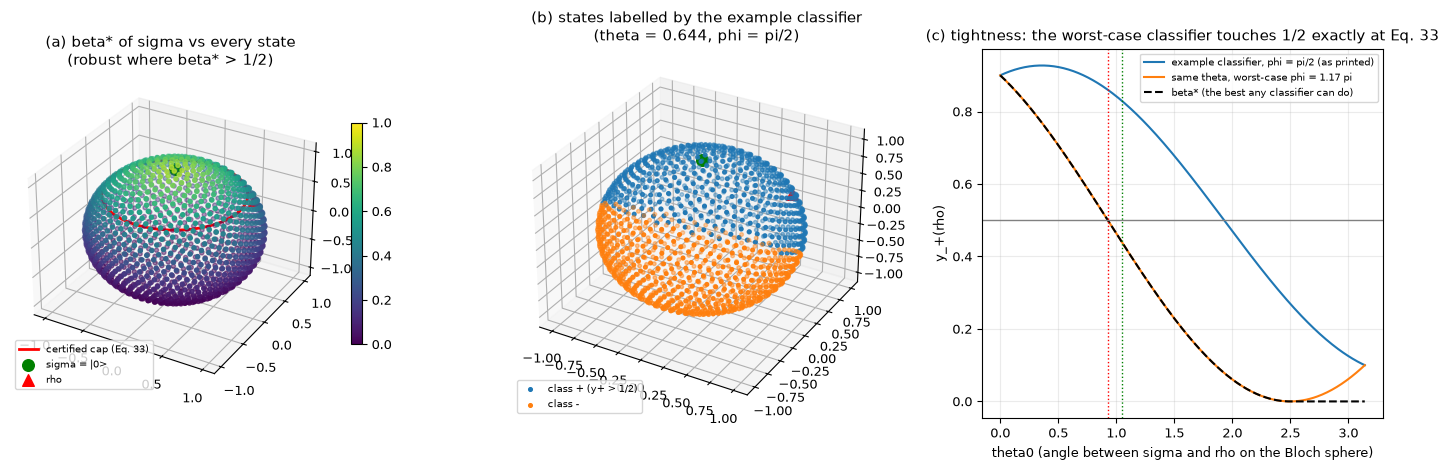

In [8]:
# ---- Part A: the paper's single-qubit example (Eqs. 23-34, Fig. 3) ----
def ket(theta, phi):
    """|psi_{theta,phi}> = cos(theta/2)|0> + sin(theta/2) e^{i phi}|1>   (Eqs. 24 and 34)."""
    return np.array([np.cos(theta / 2), np.sin(theta / 2) * np.exp(1j * phi)])

def bloch(theta, phi):
    return np.array([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)])

TH0, PH0 = np.pi / 3, np.pi / 6               # adversarial state rho of the paper
ALPHA0, PA = 0.1, 0.9                         # type-I error 0.1 = 1 - pA
ket0 = np.array([1.0, 0.0], complex)
sigma_t, rho_t = proj(ket0), proj(ket(TH0, PH0))

# (a) hypothesis-testing view: beta*_{0.1}(sigma, rho)   (Eq. 31 says about 0.44)
beta_dual = beta_star(sigma_t, rho_t, ALPHA0)
beta_closed = float(beta_pure(np.cos(TH0 / 2) ** 2, ALPHA0))
eta_paper = (9 - np.sqrt(3)) / np.sqrt(30) * ket0 - 3 * np.sqrt(2 / 5) * ket(TH0, PH0)       # Eq. (30) as printed
beta_eq31 = 1 - abs(np.vdot(eta_paper, ket(TH0, PH0))) ** 2
M_opt, t_opt = helstrom_operator(sigma_t, rho_t, ALPHA0)
print(f"|eta_1> of Eq. (30): norm = {np.linalg.norm(eta_paper):.6f},  alpha = |<eta|0>|^2 = {abs(np.vdot(eta_paper, ket0)) ** 2:.6f}")
print(f"beta* from Eq. (31) with the printed |eta_1> : {beta_eq31:.4f}")
print(f"beta* from the SDP dual (this notebook)      : {beta_dual:.4f}   closed form for pure states: {beta_closed:.4f}")
print(f"Helstrom operator M_t equals |eta_1><eta_1| of Eq. (30): {np.allclose(M_opt, proj(eta_paper), atol=1e-6)}   (t* = {t_opt:.4f})")
print(f"beta* = {beta_dual:.4f} < 1/2  ->  rho is NOT guaranteed to get the class of sigma (pA = {PA})")
add_claim("A1", "Eq. 31", "optimal type-II error beta* for theta0=pi/3, phi0=pi/6, alpha0=0.1", "~0.44", f"{beta_dual:.4f}",
          verdict_num(0.44, beta_dual))

# (b) classification-robustness view: radius in theta0 (Eq. 33)
theta_crit = 2 * np.arccos(np.sqrt(0.5 + np.sqrt(PA * (1 - PA))))
th_scan = np.linspace(0.01, np.pi - 0.01, 700)
beta_scan = np.array([beta_star(sigma_t, proj(ket(t_, PH0)), 1 - PA) for t_ in th_scan])
th_num = th_scan[np.argmax(beta_scan <= 0.5)]              # first angle at which beta* drops to 1/2
print(f"\ncertified angle (Eq. 33): theta0 < 2 arccos(sqrt(0.8)) = {theta_crit:.4f} rad   (paper: ~0.93 < pi/3 = {np.pi / 3:.4f})")
print(f"numerical boundary of {{beta* > 1/2}} from the SDP : {th_num:.4f} rad  (grid step {th_scan[1] - th_scan[0]:.4f})")
add_claim("A2", "Eq. 33", "maximal certified angle theta0 for pA = 0.9", "~0.93 rad", f"{theta_crit:.4f} (SDP boundary {th_num:.3f})",
          verdict_num(0.93, theta_crit))
add_claim("A3", "Eq. 34", "classifier angle theta = 2 arccos(sqrt 0.9)", "~0.644 rad", f"{2 * np.arccos(np.sqrt(0.9)):.4f}",
          verdict_num(0.644, 2 * np.arccos(np.sqrt(0.9)), 0.002))

# (c) the example classifier {Pi_{theta,phi}, 1 - Pi_{theta,phi}} with theta = 0.644, phi = pi/2
TH_C = 2 * np.arccos(np.sqrt(0.9))
def y_plus(state_dm, theta=TH_C, phi=np.pi / 2):
    return float(np.real(np.trace(proj(ket(theta, phi)) @ state_dm)))
y_s, y_r = y_plus(sigma_t), y_plus(rho_t)
print(f"\nexample classifier (phi = pi/2, as printed): y_+(sigma) = {y_s:.4f}, y_+(rho) = {y_r:.4f}")
print(f"   -> A(sigma) = {'+' if y_s > .5 else '-'},  A(rho) = {'+' if y_r > .5 else '-'}   (the paper states A(rho) != A(sigma))")
phis = np.linspace(0, 2 * np.pi, 721)
y_rho_phi = np.array([y_plus(rho_t, TH_C, p_) for p_ in phis])
phi_worst = phis[np.argmin(y_rho_phi)]
print(f"scanning the azimuth phi of the classifier: y_+(sigma) stays {y_plus(sigma_t):.4f}; the minimum of y_+(rho) is {y_rho_phi.min():.4f} "
      f"at phi = {phi_worst:.3f} rad = {phi_worst / np.pi:.3f} pi  (= pi/6 + pi, i.e. opposite to the azimuth of rho)")
flip_phis = phis[y_rho_phi < 0.5]
print(f"the classifier flips rho for {len(flip_phis)} of {len(phis)} azimuths, between phi = {flip_phis.min() / np.pi:.2f} pi and {flip_phis.max() / np.pi:.2f} pi;"
      f" phi = pi/2 is {'inside' if np.any(np.isclose(flip_phis, np.pi / 2, atol=0.005)) else 'outside'} that window")
add_claim("A4", "p. 8", "the example classifier (phi = pi/2) classifies rho differently from sigma", "A(rho) != A(sigma)",
          f"y+(rho) = {y_r:.3f} > 1/2: same class",
          "not reached" if y_r > 0.5 else "reproduced",
          f"flip happens for the worst-case azimuth phi = 7pi/6 (y+(rho) = {y_rho_phi.min():.4f} = beta*)")
add_claim("A5", "Thm 2 / Eq. 59", "a classifier with y(sigma)=0.9 and y(rho)=beta* <= 1/2 exists", "exists", f"phi=7pi/6: y(rho)={y_rho_phi.min():.4f}",
          "reproduced" if abs(y_rho_phi.min() - beta_dual) < 1e-3 and y_rho_phi.min() < 0.5 else "not reached")

# ---- Fig. 3 redrawn: Bloch sphere coloured by beta*, labelled states, and the tightness curve ----
n_pts = 1500
k_ = np.arange(n_pts) + 0.5
th_s = np.arccos(1 - 2 * k_ / n_pts); ph_s = np.pi * (1 + 5 ** 0.5) * k_
bl = np.stack([np.sin(th_s) * np.cos(ph_s), np.sin(th_s) * np.sin(ph_s), np.cos(th_s)], 1)
F_s = np.cos(th_s / 2) ** 2
beta_s = beta_pure(F_s, ALPHA0)
n_dec = bloch(TH_C, np.pi / 2)
cls_s = np.sign(bl @ n_dec)
fig = plt.figure(figsize=(14, 4.6))
ax = fig.add_subplot(1, 3, 1, projection="3d")
sc = ax.scatter(*bl.T, c=beta_s, cmap="viridis", s=9, vmin=0, vmax=1)
cap = np.linspace(0, 2 * np.pi, 100)
ax.plot(np.sin(theta_crit) * np.cos(cap), np.sin(theta_crit) * np.sin(cap), np.cos(theta_crit) * np.ones_like(cap), "r-", lw=2, label="certified cap (Eq. 33)")
ax.scatter(*bloch(0, 0), c="g", s=70, label="sigma = |0>"); ax.scatter(*bloch(TH0, PH0), c="r", s=70, marker="^", label="rho")
ax.set_title("(a) beta* of sigma vs every state\n(robust where beta* > 1/2)"); ax.legend(fontsize=7, loc="lower left"); fig.colorbar(sc, ax=ax, shrink=0.6)
ax = fig.add_subplot(1, 3, 2, projection="3d")
ax.scatter(*bl[cls_s > 0].T, c="tab:blue", s=7, label="class + (y+ > 1/2)"); ax.scatter(*bl[cls_s < 0].T, c="tab:orange", s=7, label="class -")
ax.scatter(*bloch(0, 0), c="g", s=70); ax.scatter(*bloch(TH0, PH0), c="r", s=70, marker="^")
ax.set_title("(b) states labelled by the example classifier\n(theta = 0.644, phi = pi/2)"); ax.legend(fontsize=7, loc="lower left")
ax = fig.add_subplot(1, 3, 3)
th_line = np.linspace(0, np.pi, 300)
ax.plot(th_line, [y_plus(proj(ket(t_, PH0))) for t_ in th_line], label="example classifier, phi = pi/2 (as printed)")
ax.plot(th_line, [y_plus(proj(ket(t_, PH0)), TH_C, phi_worst) for t_ in th_line], label=f"same theta, worst-case phi = {phi_worst / np.pi:.2f} pi")
ax.plot(th_line, beta_pure(np.cos(th_line / 2) ** 2, ALPHA0), "k--", label="beta* (the best any classifier can do)")
ax.axhline(0.5, color="gray", lw=1); ax.axvline(theta_crit, color="r", lw=1, ls=":"); ax.axvline(TH0, color="g", lw=1, ls=":")
ax.set_xlabel("theta0 (angle between sigma and rho on the Bloch sphere)"); ax.set_ylabel("y_+(rho)")
ax.set_title("(c) tightness: the worst-case classifier touches 1/2 exactly at Eq. 33"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Theorems 1-3 on random states and random measurements

The theory makes three kinds of statements; each gets its own randomised test.

* **Theorem 1 (soundness).** Draw a random state `sigma` (dimension 2, 4 or 8, pure or mixed), a random `K`-outcome projective
  measurement (K = 2, 3, 4, optionally blurred with the uniform POVM), read off `pA` and `pB` from the measurement itself, then
  move the state away from `sigma` with random unitary rotations of growing strength, mixed with random noise. Whenever
  condition (10) holds, the classifier must not change its answer. Zero violations are expected, and we also record how much further
  than the certified strength the specific classifier flips.
* **Theorem 2 (tightness).** For random pairs `(sigma, rho)` and `pA` build the Helstrom operator `M`, the classifier `A*` with POVM
  `{1 - M, M}`, and check that it is consistent (`y_A(sigma) = pA`) and that it flips `rho` exactly when (10) is violated.
* **Lemma 1 and Theorem 3 (closed forms).** For pure states the SDP condition (10) must coincide with `F > (1 + sqrt g)/2`
  (also for `pA + pB < 1`); for mixed states the fidelity condition must be sufficient. The Uhlmann fidelity routine is checked
  against `qiskit.quantum_info.state_fidelity`.

In [9]:
# ---- Theorem 1 (soundness), Theorem 2 (tightness) and Lemma 1 / Theorem 3 (closed forms) on random states and classifiers ----
from scipy.linalg import expm

def random_projective_povm(dim, K, rng, noise=0.0):
    """Random K-outcome measurement: a random orthonormal basis split into K groups (+ optional mixing with the uniform POVM)."""
    Q, _ = np.linalg.qr(rng.normal(size=(dim, dim)) + 1j * rng.normal(size=(dim, dim)))
    groups = np.array_split(rng.permutation(dim), K)
    Lam = [(Q[:, g] @ dag(Q[:, g])) for g in groups]
    return [(1 - noise) * L + noise * np.eye(dim) / K for L in Lam]

def confident_state(Lam, kA, rng, mix):
    """A random state concentrated on the support of effect kA (so that pA is large), mixed with `mix` random noise."""
    w, v = np.linalg.eigh(Lam[kA])
    sup = v[:, w > 0.5]
    psi = sup @ (rng.normal(size=sup.shape[1]) + 1j * rng.normal(size=sup.shape[1]))
    s = proj(psi / np.linalg.norm(psi))
    return (1 - mix) * s + mix * random_state(Lam[0].shape[0], rng)

n_trials = N_RANDOM_TRIALS
n_checked = n_cert = n_viol = 0
ratios = []                                      # (true flip distance) / (certified distance) along each path, for the specific classifier
kind_counts = {"d=2,K=2": 0, "d=4,K=2": 0, "d=4,K=3": 0, "d=8,K=3": 0, "d=8,K=4": 0}
cfg = list(kind_counts)
t_a = time.time()
for it in range(n_trials):
    key = cfg[it % len(cfg)]
    dim, K = int(key[2:key.index(",")]), int(key[key.index("K=") + 2:])
    Lam = random_projective_povm(dim, K, rng, noise=rng.uniform(0, 0.4))
    kA0 = rng.integers(K)
    sigma = confident_state(Lam, kA0, rng, mix=rng.uniform(0, 0.4))
    y_s = np.array([np.trace(L @ sigma).real for L in Lam])
    kA = int(np.argmax(y_s)); pA = y_s[kA]; pB = np.delete(y_s, kA).max()
    if pA <= 0.5 and K == 2:
        continue
    H = rng.normal(size=(dim, dim)) + 1j * rng.normal(size=(dim, dim)); H = (H + dag(H)) / 2
    Hn = H / np.linalg.norm(H, 2)
    noise_state = random_state(dim, rng)
    flip_s, cert_s = None, 0.0
    for s in np.linspace(0, 1.2, 10)[1:]:
        U = expm(-1j * s * Hn)
        rho = U @ sigma @ dag(U)
        rho = (1 - 0.3 * s) * rho + 0.3 * s * noise_state                 # unitary rotation + mixing with noise (mixed adversarial states)
        n_checked += 1
        cond = beta_star(sigma, rho, 1 - pA) + beta_star(sigma, rho, pB) > 1 + 1e-9            # Eq. (10)
        y_r = np.array([np.trace(L @ rho).real for L in Lam])
        flipped = int(np.argmax(y_r)) != kA
        if cond:
            n_cert += 1; cert_s = s
            if flipped:
                n_viol += 1
        if flipped and flip_s is None:
            flip_s = s
    kind_counts[key] += 1
    if flip_s is not None and cert_s > 0:
        ratios.append(flip_s / cert_s)
print(f"Theorem 1: {n_trials} random (state, classifier) pairs, {n_checked} perturbed states tested "
      f"({', '.join(f'{k}: {v}' for k, v in kind_counts.items())})")
print(f"   states with the QHT condition (10) true : {n_cert}   ->  of which the classifier changed its answer: {n_viol}")
print(f"   along each perturbation path the classifier first flips at {np.median(ratios):.2f}x (median) the last certified strength "
      f"({len(ratios)} paths): the certificate is sound, and conservative for a specific classifier ({time.time() - t_a:.0f}s)")
assert n_viol == 0
add_claim("T1", "Thm 1", "no classifier consistent with (pA, pB) changes its answer when beta*_{1-pA} + beta*_{pB} > 1",
          "guaranteed", f"{n_viol} violations in {n_cert} certified states", "reproduced" if n_viol == 0 else "not reached")

# ---- Theorem 2: build the worst-case classifier A* from the Helstrom operator and test it ----
n2 = N_RANDOM_TRIALS
mis_consist = mis_flip = n_flip = n_rob = 0
for it in range(n2):
    dim = [2, 3, 4, 6][it % 4]
    sigma = random_state(dim, rng, rank=int(rng.integers(1, dim + 1)))
    rho = random_state(dim, rng, rank=int(rng.integers(1, dim + 1)))
    if it % 2 == 0:                                    # bring rho closer to sigma half of the time
        rho = (1 - rng.uniform(0.5, 0.95)) * rho + rng.uniform(0.5, 0.95) * sigma
        rho /= np.trace(rho).real
    pA = rng.uniform(0.52, 0.99)
    M, _ = helstrom_operator(sigma, rho, 1 - pA)       # classifier A*: POVM {1 - M, M}, class A <-> 1 - M
    yA_s, yA_r = np.trace(sigma @ (np.eye(dim) - M)).real, np.trace(rho @ (np.eye(dim) - M)).real
    b = beta_star(sigma, rho, 1 - pA)
    if abs(yA_s - pA) > 1e-6:
        mis_consist += 1
    robust = b > 0.5
    flips = yA_r <= 0.5 + 1e-9
    n_flip += int(flips); n_rob += int(robust)
    if robust == flips:                                # violating states must be flipped, robust states must not
        mis_flip += 1
print(f"Theorem 2: {n2} random pairs (dimension 2-6, pure and mixed, pA in (0.52, 0.99))")
print(f"   A* consistent with y_A(sigma) = pA in all but {mis_consist} cases;  {n_flip} pairs violate (10) and A* flips every one of them;"
      f" {n_rob} pairs satisfy (10) and A* keeps the class;  disagreements: {mis_flip}")
assert mis_consist == 0 and mis_flip == 0
add_claim("T2", "Thm 2", "when (10) is violated (pA + pB = 1) a consistent classifier A* flips rho", "exists",
          f"A* built for {n_flip} violating pairs, {mis_flip} failures", "reproduced" if mis_flip == 0 and mis_consist == 0 else "not reached")

# ---- Lemma 1: the closed-form fidelity condition (12) is equivalent to the SDP condition (10) for pure states ----
n_l = 20000 if not FAST_MODE else 5000
pA_ = rng.uniform(0.5, 1, n_l); pB_ = rng.uniform(0, 1, n_l) * (1 - pA_)         # pA + pB <= 1, pB <= 1 - pA < pA
rF_ = r_fid(pA_, pB_)
F_ = np.clip(rF_ + rng.uniform(-0.03, 0.03, n_l), 0, 1)                               # fidelities straddling the boundary
cond10 = beta_pure(F_, 1 - pA_) + beta_pure(F_, pB_) > 1
cond12 = F_ > rF_
mism = int(np.sum(cond10 != cond12))
# the same with the generic SDP solver on a subsample (also pure states, dimension 5)
mism_sdp = 0
for i in range(150):
    s_, r_ = random_pure_vec(5, rng), random_pure_vec(5, rng)
    Fv = abs(np.vdot(s_, r_)) ** 2
    pa, pb = rng.uniform(0.55, 0.99), 0.0
    pb = rng.uniform(0, 1 - pa)
    c10 = beta_star(proj(s_), proj(r_), 1 - pa) + beta_star(proj(s_), proj(r_), pb) > 1
    mism_sdp += int(c10 != (Fv > r_fid(pa, pb)))
print(f"Lemma 1: condition (10) versus fidelity condition (12) on {n_l} draws (closed-form beta) and 150 draws (SDP dual): mismatches {mism} and {mism_sdp}")
add_claim("L1", "Lemma 1", "SDP condition (10) <=> F > (1+sqrt g)/2 for pure states", "equivalent", f"{mism + mism_sdp} mismatches in {n_l + 150}",
          "reproduced" if mism + mism_sdp == 0 else "not reached")

# ---- Theorem 3: fidelity bound for MIXED states (and the Uhlmann fidelity routine checked against Qiskit) ----
chk = random_state(4, rng), random_state(4, rng)
assert abs(uhlmann_fidelity(*chk) - state_fidelity(DensityMatrix(chk[0]), DensityMatrix(chk[1]))) < 1e-9
n_m = 600 if FAST_MODE else 4000
suff_viol = n_suff = n_cons = n_below = 0
for i in range(n_m):
    dim = [2, 3, 4][i % 3]
    pa = rng.uniform(0.55, 0.98); pb = 1 - pa
    s_ = random_state(dim, rng, rank=int(rng.integers(1, dim + 1)))
    mix = rng.uniform(0.02, 0.9)
    r_ = (1 - mix) * s_ + mix * random_state(dim, rng, rank=int(rng.integers(1, dim + 1)))
    Fv = uhlmann_fidelity(s_, r_)
    c10 = beta_star(s_, r_, 1 - pa) + beta_star(s_, r_, pb) > 1
    if Fv > r_fid(pa, pb):
        n_suff += 1
        suff_viol += int(not c10)
    else:
        n_below += 1
        n_cons += int(c10)
print(f"Theorem 3 (mixed states, {n_m} random pairs): F > r_F in {n_suff} cases, condition (10) failed in {suff_viol} of them (sufficiency).")
print(f"   F <= r_F in {n_below} cases, (10) still holds in {n_cons} ({100 * n_cons / max(n_below, 1):.0f}%): for a given mixed pair the fidelity bound can be"
      " conservative, but it is exact for the worst case (pure states, Lemma 1).")
add_claim("T3", "Thm 3", "F(rho, sigma) > (1+sqrt g)/2 is sufficient for mixed states", "sufficient", f"{suff_viol} violations in {n_suff} pairs",
          "reproduced" if suff_viol == 0 else "not reached")

Theorem 1: 400 random (state, classifier) pairs, 3600 perturbed states tested (d=2,K=2: 80, d=4,K=2: 80, d=4,K=3: 80, d=8,K=3: 80, d=8,K=4: 80)
   states with the QHT condition (10) true : 1992   ->  of which the classifier changed its answer: 0
   along each perturbation path the classifier first flips at 2.25x (median) the last certified strength (49 paths): the certificate is sound, and conservative for a specific classifier (114s)


Theorem 2: 400 random pairs (dimension 2-6, pure and mixed, pA in (0.52, 0.99))
   A* consistent with y_A(sigma) = pA in all but 0 cases;  251 pairs violate (10) and A* flips every one of them; 149 pairs satisfy (10) and A* keeps the class;  disagreements: 0


Lemma 1: condition (10) versus fidelity condition (12) on 20000 draws (closed-form beta) and 150 draws (SDP dual): mismatches 0 and 0


Theorem 3 (mixed states, 4000 random pairs): F > r_F in 1276 cases, condition (10) failed in 0 of them (sufficiency).
   F <= r_F in 2724 cases, (10) still holds in 717 (26%): for a given mixed pair the fidelity bound can be conservative, but it is exact for the worst case (pure states, Lemma 1).


## 4. Trace-distance bounds compared (Fig. 2, Lemma 2, Corollary 1)

Three trace-distance radii for the same confidence: `r_Q` (Eq. 16, QHT, for *pure* adversarial states), `r_H = (pA - pB)/2` (Lemma 2,
Holder duality, any states) and `r~_Q` (Eq. 21, QHT with a pure benign state and a *mixed* adversary, obtained from a convex-hull
argument). The paper's Fig. 2 and text say `r_Q > r_H > r~_Q` everywhere. The first cell re-draws the two contour plots and counts
the fraction of the `(pA, pB)` grid where each inequality holds; the second cell goes one step further than the paper and
computes the **exact** trace-distance radius for a pure benign state and mixed adversaries by walking along random segments
`rho(s) = sigma + s (rho_0 - sigma)` until condition (10) fails (`beta*` is concave in `rho`, so the robust set along a segment is
an interval and bisection is exact). The smallest exit distance over many directions is compared with the three formulas.

grid of (pA, pB) with pA + pB <= 1: 3321 points
  r_Q > r_H        : 100.0% of the points   (paper: always)
  r_H > r~_Q (literal delta)   : 100.0%      r_H > r~_Q (delta = r_Q) : 100.0%   (paper: always)


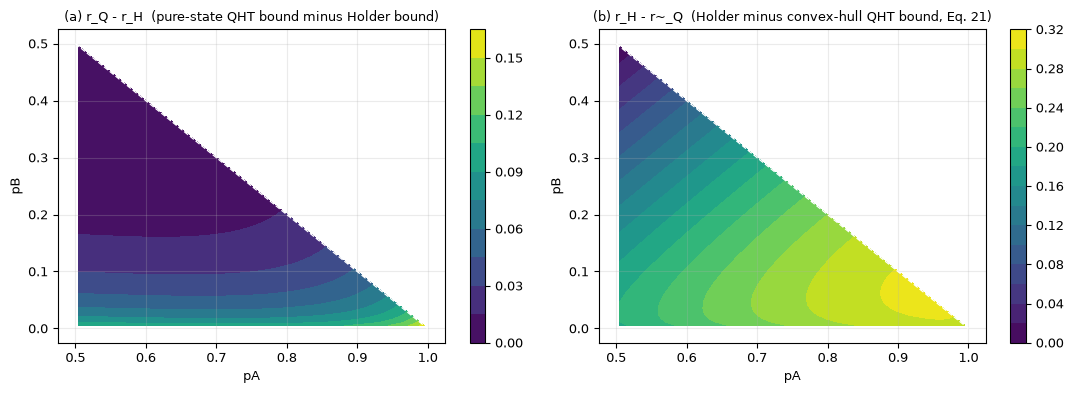


Smallest trace distance at which a (pure benign, mixed adversarial) pair stops satisfying the exact condition (10) - 80 random directions per row (120s):
 dim   pA  exact_min_over_directions  r_Q_pure  r_H  r_tilde_literal  r_tilde_rQ
   2 0.60                     0.1000    0.1005 0.10           0.0014      0.0005
   2 0.75                     0.2500    0.2588 0.25           0.0228      0.0088
   2 0.90                     0.4000    0.4472 0.40           0.0992      0.0472
   4 0.60                     0.1013    0.1005 0.10           0.0014      0.0005
   4 0.75                     0.2507    0.2588 0.25           0.0228      0.0088
   4 0.90                     0.4000    0.4472 0.40           0.0992      0.0472



Holder bound r_H is below the exact radius in all rows: True;  r~_Q (literal) below exact: True;  r~_Q (delta = r_Q) below exact: True
pure-state radius r_Q exceeds the exact mixed-adversary radius in some row (so it must not be used for mixed states): True
in dimension 2 the smallest radius over the sampled directions equals the Holder radius to 0.0e+00: for a pure benign state and mixed adversaries the Holder bound is already attained, so the trace-distance QHT bound cannot be better there.


In [10]:
# ---- Fig. 2: trace-distance bounds  r_Q (Eq. 16, QHT, pure)  vs  r_H (Eq. 22, Holder)  vs  r~_Q (Eq. 21, QHT, mixed adversary) ----
def r_tilde(pA, pB, reading="literal"):
    """Corollary 1, Eq. (21): T < delta (1 - sqrt(1 - delta^2)).  The PDF text prints delta = [ (1 - g)/2 ]^(1/2)  ("literal"),
    which differs from the pure-state radius r_Q = [ (1 - sqrt g)/2 ]^(1/2) ("rQ" reading); both readings are tested."""
    G = g_fun(pA, pB)
    delta = np.sqrt(0.5 * (1 - G)) if reading == "literal" else np.sqrt(0.5 * (1 - np.sqrt(G)))
    return delta * (1 - np.sqrt(1 - delta ** 2))

pa_g = np.linspace(0.505, 0.995, GRID); pb_g = np.linspace(0.005, 0.495, GRID)
PAg, PBg = np.meshgrid(pa_g, pb_g)
valid = (PAg + PBg <= 1.0) & (PBg < PAg)
rQ_g, rH_g = r_trace_qht_pure(PAg, PBg), r_trace_holder(PAg, PBg)
rT_lit, rT_q = r_tilde(PAg, PBg, "literal"), r_tilde(PAg, PBg, "rQ")
frac = lambda m: float(np.mean(m[valid]))
print(f"grid of (pA, pB) with pA + pB <= 1: {int(valid.sum())} points")
print(f"  r_Q > r_H        : {100 * frac(rQ_g > rH_g):.1f}% of the points   (paper: always)")
print(f"  r_H > r~_Q (literal delta)   : {100 * frac(rH_g > rT_lit):.1f}%      r_H > r~_Q (delta = r_Q) : {100 * frac(rH_g > rT_q):.1f}%   (paper: always)")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, Z, ttl in [(ax[0], rQ_g - rH_g, "(a) r_Q - r_H  (pure-state QHT bound minus Holder bound)"),
                   (ax[1], rH_g - rT_lit, "(b) r_H - r~_Q  (Holder minus convex-hull QHT bound, Eq. 21)")]:
    Zm = np.where(valid, Z, np.nan)
    cs = a_.contourf(PAg, PBg, Zm, levels=14, cmap="viridis"); plt.colorbar(cs, ax=a_)
    a_.plot([0.5, 1], [0.5, 0], "w--", lw=1); a_.set_xlabel("pA"); a_.set_ylabel("pB"); a_.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()

# ---- exact trace-distance radius for a PURE benign state and MIXED adversarial states (what Corollary 1 is about) ----
def exit_trace_distance(sigma, rho0, pA, iters=16):
    """Along rho(s) = sigma + s (rho0 - sigma): beta* is concave in s, so {beta* > 1/2} is an interval [0, s*). Return T(rho(s*), sigma)."""
    f = lambda s: beta_star(sigma, sigma + s * (rho0 - sigma), 1 - pA) - 0.5
    if f(1.0) > 0:
        return np.inf
    lo, hi = 0.0, 1.0
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if f(mid) > 0 else (lo, mid)
    return lo * trace_distance(rho0, sigma)

rows2 = []
t_b = time.time()
for dim in [2, 4]:
    for pA in [0.6, 0.75, 0.9]:
        sig = proj(random_pure_vec(dim, rng))
        Ts = []
        for _ in range(N_MIXED_DIRS):
            rk = 1 if rng.random() < 0.5 else int(rng.integers(1, dim + 1))
            Ts.append(exit_trace_distance(sig, random_state(dim, rng, rank=rk), pA))
        T_min = float(np.min(Ts))
        rows2.append(dict(dim=dim, pA=pA, exact_min_over_directions=T_min, r_Q_pure=float(r_trace_qht_pure(pA)), r_H=float(r_trace_holder(pA)),
                          r_tilde_literal=float(r_tilde(pA, 1 - pA, "literal")), r_tilde_rQ=float(r_tilde(pA, 1 - pA, "rQ"))))
tab2 = pd.DataFrame(rows2).round(4)
print(f"\nSmallest trace distance at which a (pure benign, mixed adversarial) pair stops satisfying the exact condition (10)"
      f" - {N_MIXED_DIRS} random directions per row ({time.time() - t_b:.0f}s):")
print(tab2.to_string(index=False))
sound_H = bool((tab2.exact_min_over_directions >= tab2.r_H - 1e-6).all())
sound_lit = bool((tab2.exact_min_over_directions >= tab2.r_tilde_literal - 1e-6).all())
sound_q = bool((tab2.exact_min_over_directions >= tab2.r_tilde_rQ - 1e-6).all())
pure_ext = bool((tab2.exact_min_over_directions < tab2.r_Q_pure - 1e-6).any())
print(f"\nHolder bound r_H is below the exact radius in all rows: {sound_H};  r~_Q (literal) below exact: {sound_lit};  r~_Q (delta = r_Q) below exact: {sound_q}")
print(f"pure-state radius r_Q exceeds the exact mixed-adversary radius in some row (so it must not be used for mixed states): {pure_ext}")
hold_gap = float((tab2.exact_min_over_directions - tab2.r_H).abs().min())
print(f"in dimension 2 the smallest radius over the sampled directions equals the Holder radius to {float((tab2[tab2.dim == 2].exact_min_over_directions - tab2[tab2.dim == 2].r_H).abs().max()):.1e}:"
      " for a pure benign state and mixed adversaries the Holder bound is already attained, so the trace-distance QHT bound cannot be better there.")
add_claim("C1", "Cor. 1", "T(rho, sigma) < r~_Q (Eq. 21) is a sufficient condition for a pure benign and a mixed adversarial state", "sufficient",
          f"below the exact radius in all {len(tab2)} (dimension, pA) rows for both readings of delta: {sound_lit and sound_q}", "reproduced" if (sound_lit and sound_q) else "not reached")
add_claim("F2a", "Fig. 2a", "pure-state QHT trace-distance bound r_Q is larger than the Holder bound r_H for every (pA, pB)", "always", f"{100 * frac(rQ_g > rH_g):.1f}% of grid",
          "reproduced" if frac(rQ_g > rH_g) > 0.999 else "not reached")
add_claim("F2b", "Fig. 2b", "Holder bound r_H is larger than the convex-hull bound r~_Q (Eq. 21) for every (pA, pB)", "always",
          f"{100 * frac(rH_g > rT_lit):.1f}% of grid (literal Eq. 21); sound: {sound_lit}", "reproduced" if frac(rH_g > rT_lit) > 0.999 else "not reached")

## 5. Robustness against known noise models (Fig. 4, Eqs. 37-40)

If the perturbation is a known channel `N_gamma` (phase damping or amplitude damping) acting on a pure input
`alpha|0> + beta|1>`, Theorem 3 turns into a bound on the noise strength: `F(sigma, N_gamma(sigma)) > r_F` rearranged for `gamma`.
The cell (i) asserts that the Kraus operators of the paper are exactly those of `qiskit_aer`'s `phase_damping_error` and
`amplitude_damping_error`, (ii) compares the closed forms (38) and (40) with a bisection on the *real channel* over a grid of
`(|alpha|^2, pA)`, (iii) re-draws Fig. 4 and checks the boundary behaviour the paper points out, and (iv) asks the question the
paper's wording "tight robustness conditions on parameters for amplitude and phase damping" invites: is the fidelity-based bound
also *necessary for this particular noisy state*, i.e. does it match the exact SDP condition (10) for `rho = N_gamma(sigma)`?

OK: paper Kraus operators (37) and (39) == qiskit_aer phase_damping_error / amplitude_damping_error


max |gamma_max (closed form of the paper) - gamma_max (bisection on the real channel)| over 125 (|alpha|^2, pA) points:
   phase    : 2.88e-14
   amplitude: 2.81e-14
   (|alpha|^2 < 1/2 for amplitude damping uses the same expression continued analytically; the check above includes those points)


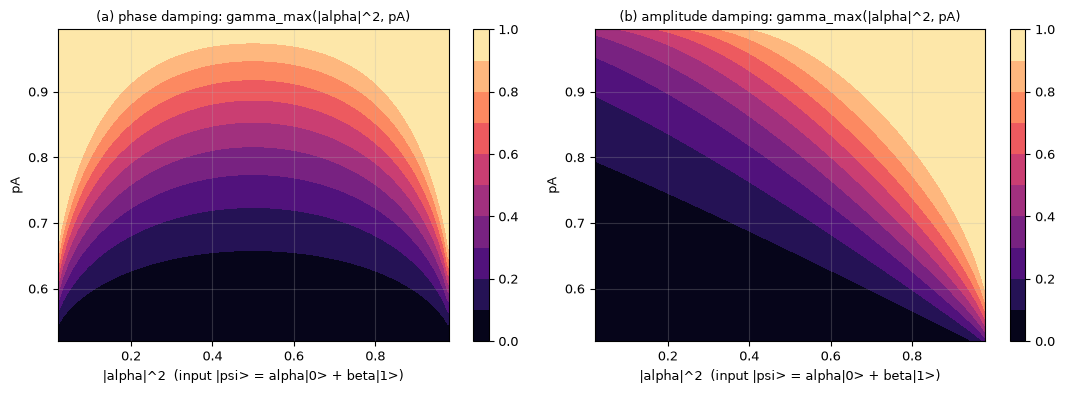

gamma_max at pA = 0.9 for |alpha|^2 = 1e-4, 0.5, 1 - 1e-4:   phase [1.   0.64 1.  ]   amplitude [0.2  0.64 1.  ]
paper: phase damping robust for every gamma <= 1 as |alpha|^2 -> 0 or 1;  amplitude damping robust for every gamma <= 1 as |alpha|^2 -> 1



Fidelity-based bound (Eqs. 38/40) versus the exact SDP condition (10) for this particular noisy state:
    noise  alpha2   pA  gamma_fidelity_bound  gamma_exact_SDP
    phase    0.50 0.90                0.6400           0.9877
    phase    0.80 0.90                0.8594           1.0000
    phase    0.80 0.75                0.3748           0.8974
    phase    0.95 0.90                1.0000           1.0000
amplitude    0.50 0.90                0.6400           0.7136
amplitude    0.80 0.90                1.0000           1.0000
amplitude    0.80 0.75                0.7346           0.7658
amplitude    0.95 0.90                1.0000           1.0000
The fidelity bound is sound (gamma_fidelity_bound <= gamma_exact_SDP) but, for one specific mixed output state, it can be conservative:
its tightness (Theorem 3) is a statement about the worst case over all states at that fidelity, not about N_gamma(sigma) itself.


In [11]:
# ---- Fig. 4: robustness against known noise models (phase damping Eq. 37-38, amplitude damping Eq. 39-40) ----
def kraus_phase(g):
    return [np.array([[1, 0], [0, np.sqrt(1 - g)]], complex), np.array([[0, 0], [0, np.sqrt(g)]], complex)]
def kraus_amp(g):
    return [np.array([[1, 0], [0, np.sqrt(1 - g)]], complex), np.array([[0, np.sqrt(g)], [0, 0]], complex)]
def apply_kraus(K, rho):
    return sum(k @ rho @ dag(k) for k in K)

# (1) the Kraus operators of the paper == the Qiskit-Aer error channels (asserted)
for g_ in [0.0, 0.17, 0.5, 0.93]:
    psi_ = ket(1.234, 0.4)
    for nm, Kf, err in [("phase", kraus_phase, phase_damping_error), ("amplitude", kraus_amp, amplitude_damping_error)]:
        out_q = DensityMatrix(proj(psi_)).evolve(err(g_).to_quantumchannel()).data
        assert np.allclose(out_q, apply_kraus(Kf(g_), proj(psi_)), atol=1e-12), (nm, g_)
print("OK: paper Kraus operators (37) and (39) == qiskit_aer phase_damping_error / amplitude_damping_error")

def fid_noisy(a, g, kind):
    """F(|psi><psi|, N_g(|psi><psi|)) for |psi> = sqrt(a)|0> + sqrt(1-a)|1> (real amplitudes suffice: the fidelity depends on |alpha|^2 only)."""
    psi = np.array([np.sqrt(a), np.sqrt(1 - a)], complex)
    out = apply_kraus(kraus_phase(g) if kind == "phase" else kraus_amp(g), proj(psi))
    return float(np.real(np.vdot(psi, out @ psi)))

def gamma_max_numeric(a, rF, kind, iters=45):
    """Largest gamma in [0,1] with F(sigma, N_gamma(sigma)) > r_F  (the fidelity decreases with gamma): bisection on the real channel."""
    if fid_noisy(a, 1.0, kind) > rF:
        return 1.0
    lo, hi = 0.0, 1.0
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if fid_noisy(a, mid, kind) > rF else (lo, mid)
    return lo

def gamma_max_phase_eq38(a, rF):
    return 1 - np.maximum(0.0, 1 + (rF - 1) / (2 * a * (1 - a))) ** 2

def gamma_max_amp_eq40(a, rF):
    b = 1 - a
    d = a - b
    if abs(d) < 1e-9:                                       # |alpha|^2 = |beta|^2: limit of the expression (a quadratic degenerates)
        s = (a - rF) / (-2 * a * b) if rF > a else 0.0
        return 1 - np.clip(s, 0, 1) ** 2
    inner = 1 - d / (a * b) * np.maximum(0.0, rF - a) / a
    return 1 - np.clip(a / d * (1 - np.sqrt(np.clip(inner, 0, None))), 0, 1) ** 2

# (2) formulas (38) and (40) against the numerical bisection on the true channel
rows4 = []
for kind, fcl in [("phase", gamma_max_phase_eq38), ("amplitude", gamma_max_amp_eq40)]:
    err = 0.0
    for a in np.linspace(0.03, 0.97, 25):
        for pA in [0.55, 0.7, 0.85, 0.95, 0.99]:
            rF = float(r_fid(pA))
            err = max(err, abs(gamma_max_numeric(a, rF, kind) - float(fcl(a, rF))))
    rows4.append((kind, err))
print("max |gamma_max (closed form of the paper) - gamma_max (bisection on the real channel)| over 125 (|alpha|^2, pA) points:")
for kind, e in rows4:
    print(f"   {kind:9s}: {e:.2e}")
print("   (|alpha|^2 < 1/2 for amplitude damping uses the same expression continued analytically; the check above includes those points)")
assert all(e < 1e-6 for _, e in rows4)

# (3) re-draw Fig. 4 and the boundary behaviour claimed in the paper
a_g = np.linspace(0.02, 0.98, GRID); pA_g = np.linspace(0.52, 0.995, GRID)
AA, PP = np.meshgrid(a_g, pA_g)
RF = r_fid(PP)
Gph, Gam = gamma_max_phase_eq38(AA, RF), np.vectorize(gamma_max_amp_eq40)(AA, RF)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, Z, ttl in [(ax[0], np.clip(Gph, 0, 1), "(a) phase damping: gamma_max(|alpha|^2, pA)"), (ax[1], np.clip(Gam, 0, 1), "(b) amplitude damping: gamma_max(|alpha|^2, pA)")]:
    cs = a_.contourf(AA, PP, Z, levels=np.linspace(0, 1, 11), cmap="magma"); plt.colorbar(cs, ax=a_)
    a_.set_xlabel("|alpha|^2  (input |psi> = alpha|0> + beta|1>)"); a_.set_ylabel("pA"); a_.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()
edge = {"phase": [float(gamma_max_phase_eq38(a, float(r_fid(0.9)))) for a in (1e-4, 0.5, 1 - 1e-4)],
        "amplitude": [float(gamma_max_amp_eq40(a, float(r_fid(0.9)))) for a in (1e-4, 0.5, 1 - 1e-4)]}
print("gamma_max at pA = 0.9 for |alpha|^2 = 1e-4, 0.5, 1 - 1e-4:   phase", np.round(edge["phase"], 4), "  amplitude", np.round(edge["amplitude"], 4))
print("paper: phase damping robust for every gamma <= 1 as |alpha|^2 -> 0 or 1;  amplitude damping robust for every gamma <= 1 as |alpha|^2 -> 1")
ok_edge = edge["phase"][0] > 0.99 and edge["phase"][2] > 0.99 and edge["amplitude"][2] > 0.99
add_claim("F4a", "Fig. 4 / Eq. 38", "phase-damping bound gamma_max, robust for all gamma at |alpha|^2 -> 0 and 1", "matches Fig. 4a",
          f"closed form == channel bisection (max err {rows4[0][1]:.1e}); edges {np.round(edge['phase'], 3).tolist()}", "reproduced" if rows4[0][1] < 1e-6 and ok_edge else "not reached")
add_claim("F4b", "Fig. 4 / Eq. 40", "amplitude-damping bound gamma_max, robust for all gamma at |alpha|^2 -> 1", "matches Fig. 4b",
          f"closed form == channel bisection (max err {rows4[1][1]:.1e}); edge {edge['amplitude'][2]:.3f}", "reproduced" if rows4[1][1] < 1e-6 and ok_edge else "not reached")

# (4) is the noise-model condition also NECESSARY for the specific noisy state? compare with the exact SDP condition (10) for rho = N_gamma(sigma)
def gamma_exact_sdp(a, pA, kind, iters=30):
    psi = np.array([np.sqrt(a), np.sqrt(1 - a)], complex); s_ = proj(psi)
    K = kraus_phase if kind == "phase" else kraus_amp
    ok = lambda g: beta_star(s_, apply_kraus(K(g), s_), 1 - pA) > 0.5
    if ok(1.0):
        return 1.0
    lo, hi = 0.0, 1.0
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if ok(mid) else (lo, mid)
    return lo
rows5 = []
for kind in ["phase", "amplitude"]:
    for a, pA in [(0.5, 0.9), (0.8, 0.9), (0.8, 0.75), (0.95, 0.9)]:
        rF = float(r_fid(pA))
        gf = float(gamma_max_phase_eq38(a, rF)) if kind == "phase" else float(gamma_max_amp_eq40(a, rF))
        rows5.append(dict(noise=kind, alpha2=a, pA=pA, gamma_fidelity_bound=round(min(gf, 1), 4), gamma_exact_SDP=round(gamma_exact_sdp(a, pA, kind), 4)))
tab5 = pd.DataFrame(rows5)
print("\nFidelity-based bound (Eqs. 38/40) versus the exact SDP condition (10) for this particular noisy state:")
print(tab5.to_string(index=False))
print("The fidelity bound is sound (gamma_fidelity_bound <= gamma_exact_SDP) but, for one specific mixed output state, it can be conservative:")
print("its tightness (Theorem 3) is a statement about the worst case over all states at that fidelity, not about N_gamma(sigma) itself.")
sound_n = bool((tab5.gamma_fidelity_bound <= tab5.gamma_exact_SDP + 1e-4).all())
gap_n = float((tab5.gamma_exact_SDP - tab5.gamma_fidelity_bound).max())
add_claim("F4c", "p. 8", "the noise-parameter bounds (38)/(40) are tight (sufficient and necessary)", "tight",
          f"sufficient (sound): {sound_n}; for the specific output state the exact SDP allows up to {gap_n:.2f} more noise",
          "reproduced" if (sound_n and gap_n < 0.02) else "not reached")

## 6. Randomised inputs: depolarisation smoothing (Eqs. 41-46, Fig. 5)

Quantum randomised smoothing sends the input through `E_p(x) = (1 - p) x + p 1/d` before the classifier. If the classifier is
confident on the *smoothed* input (`y_kA(E_p(sigma)) >= pA`), robustness for `rho` follows from Theorem 1 applied to the pair
`E_p(sigma)`, `E_p(rho)`. For single-qubit pure states the paper gives the radius `r_Q(p)` in Eq. (43) (two branches), compared with
the Holder radius `r_H(p)` (Eq. 45) and the quantum-differential-privacy radius `r_DP(p)` of Du et al. (Eq. 46) in Fig. 5.
We compute the **exact** radius numerically: for two pure states with overlap `F` the operator `rho - t sigma` has two nonzero
eigenvalues (Eqs. 25-27) and `d - 2` zero ones; depolarisation scales the first two by `1 - p` and shifts all `d` by
`(p/d)(1 - t)`, which gives `beta*` of the smoothed pair in closed form, and bisection on `F` gives the radius. This reduced
formula is asserted equal to the generic SDP dual on explicit depolarised matrices (dimension 2 and 6), the channel is asserted equal to
Qiskit's `depolarizing_error`, and the same reduction is reused for the 64-dimensional classifier in Part B.

OK: E_p of Eq. (41) == qiskit_aer depolarizing_error(p, n) for n = 1, 2


OK: the cheap reset-based global depolarising error == (1-p) rho + p 1/d in Aer's density-matrix simulation (n = 1, 2, 3)


OK: reduced 2x2 formula for beta* of depolarised pure states == generic SDP dual (d = 2 and d = 6)


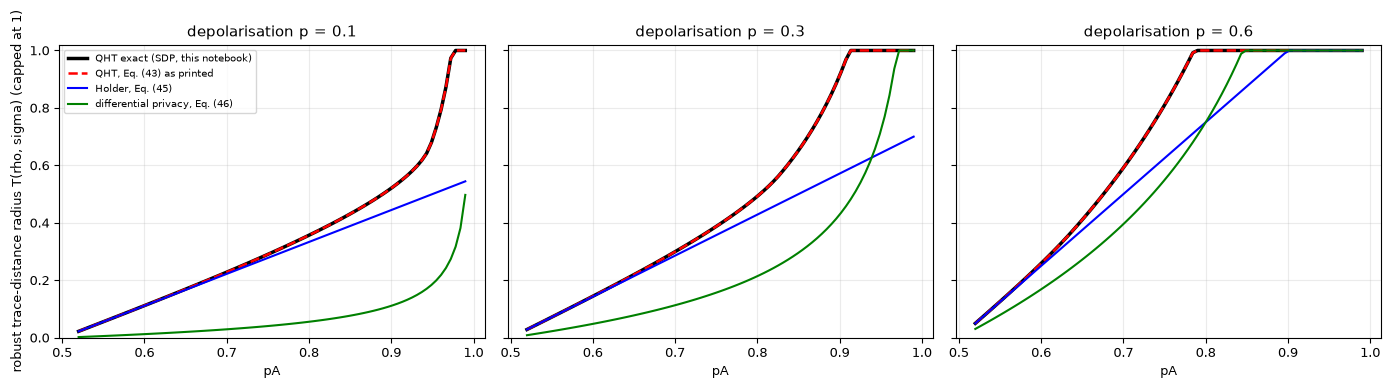

  p  max_abs_diff_Eq43_vs_exact  exact_ge_holder  exact_ge_dp  eq43_ge_holder  eq43_ge_dp
0.1                         0.0             True         True            True        True
0.3                         0.0             True         True            True        True
0.6                         0.0             True         True            True        True


In [12]:
# ---- Fig. 5: randomised inputs with depolarisation smoothing, E_p(x) = (1-p) x + p 1/d  (Eq. 41) ----
# (1) the channel == Qiskit's depolarizing_error (param p gives (1-p) rho + p tr(rho) 1/2^n), asserted for 1 and 2 qubits
for nq in (1, 2):
    dd = 2 ** nq
    st = random_state(dd, rng)
    for p_ in (0.0, 0.2, 0.7):
        out = DensityMatrix(st).evolve(depolarizing_error(p_, nq).to_quantumchannel()).data
        assert np.allclose(out, (1 - p_) * st + p_ * np.eye(dd) / dd, atol=1e-12)
print("OK: E_p of Eq. (41) == qiskit_aer depolarizing_error(p, n) for n = 1, 2")

# Qiskit's depolarizing_error on 6 qubits expands into 4096 Pauli circuits (far too slow to simulate), so the 6-qubit classifier of
# Part B uses the exact formula (1-p) rho + p/d, whose validity is established here against Qiskit (n = 1, 2) and against an Aer
# QuantumError that, with probability p, resets every qubit and flips each with probability 1/2 (a uniformly random basis state =
# the maximally mixed state), otherwise does nothing (n = 1, 2, 3; 1 + 2^n small circuits).  Part B additionally runs the real
# 19-qubit 'purified' circuit of the architecture section against the same formula.
from qiskit_aer.noise import QuantumError
def global_depolarizing_error(p, n):
    circs, probs = [QuantumCircuit(n)], [1 - p]
    for b in range(2 ** n):
        c = QuantumCircuit(n)
        for q in range(n):
            c.reset(q)
        for q in range(n):
            if (b >> q) & 1:
                c.x(q)
        circs.append(c); probs.append(p / 2 ** n)
    return QuantumError(list(zip(circs, probs)))

_sim_chk = AerSimulator(method="density_matrix")
for nq in (1, 2, 3):
    dd = 2 ** nq
    st = random_state(dd, rng)
    w_, v_ = np.linalg.eigh(st)
    for p_ in (0.15, 0.6):
        qc_ = QuantumCircuit(nq)
        qc_.set_density_matrix(DensityMatrix(st))
        qc_.append(global_depolarizing_error(p_, nq).to_instruction(), range(nq))
        qc_.save_density_matrix(label="rho")
        out = _sim_chk.run(transpile(qc_, _sim_chk), shots=1).result().data(0)["rho"]
        assert np.allclose(np.asarray(out), (1 - p_) * st + p_ * np.eye(dd) / dd, atol=1e-9), (nq, p_)
print("OK: the cheap reset-based global depolarising error == (1-p) rho + p 1/d in Aer's density-matrix simulation (n = 1, 2, 3)")

def beta_dep(F, p, pA, d, iters=70):
    """beta*_{1-pA}( E_p(sigma), E_p(rho) ) for two PURE states with overlap F in dimension d.  rho - t sigma has two eigenvalues in the
    span of the pair (Eqs. 25-27) and d - 2 zero ones; the depolarising channel shifts all of them by (p/d)(1 - t) and scales the two by (1-p)."""
    a0 = 1 - pA
    def val(t):
        root = np.sqrt((1 - t) ** 2 + 4 * t * (1 - F))
        c = p / d * (1 - t)
        pos = max((1 - p) * 0.5 * ((1 - t) + root) + c, 0) + max((1 - p) * 0.5 * ((1 - t) - root) + c, 0) + (d - 2) * max(c, 0)
        return 1 - t * a0 - pos
    lo, hi = 0.0, 1.0 / a0 + 1.0
    gr = (np.sqrt(5) - 1) / 2
    x1, x2 = hi - gr * (hi - lo), lo + gr * (hi - lo)
    f1, f2 = val(x1), val(x2)
    for _ in range(iters):
        if f1 < f2:
            lo, x1, f1 = x1, x2, f2; x2 = lo + gr * (hi - lo); f2 = val(x2)
        else:
            hi, x2, f2 = x2, x1, f1; x1 = hi - gr * (hi - lo); f1 = val(x1)
    return max(val(0.0), f1, f2)

# the reduced formula == the generic SDP dual on explicit depolarised density matrices (dimension 2 and 6)
for dd in (2, 6):
    for _ in range(12):
        s_, r_ = random_pure_vec(dd, rng), random_pure_vec(dd, rng)
        p_, pa_ = rng.uniform(0, 0.8), rng.uniform(0.55, 0.98)
        Es = lambda v: (1 - p_) * proj(v) + p_ * np.eye(dd) / dd
        assert abs(beta_star(Es(s_), Es(r_), 1 - pa_) - beta_dep(abs(np.vdot(s_, r_)) ** 2, p_, pa_, dd)) < 1e-7
print("OK: reduced 2x2 formula for beta* of depolarised pure states == generic SDP dual (d = 2 and d = 6)")

def F_crit_dep(p, pA, d):
    """Smallest fidelity F between the (pure) input states with beta*(E_p sigma, E_p rho) > 1/2:  robust iff F > F_crit."""
    if beta_dep(0.0, p, pA, d) > 0.5:
        return 0.0
    lo, hi = 0.0, 1.0
    for _ in range(45):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if beta_dep(mid, p, pA, d) > 0.5 else (mid, hi)
    return hi

def rQ_exact_dep(p, pA, d=2):
    return np.sqrt(1 - F_crit_dep(p, pA, d))                    # trace distance of the pure input pair, T = sqrt(1 - F)

def rQ_eq43(p, pA):
    """Eq. (43) as printed (single-qubit pure states, pA + pB = 1):  two branches separated by pA_c = (1 + 3(1-p)^2) / (2 + 2(1-p)^2)."""
    pA_c = (1 + 3 * (1 - p) ** 2) / (2 + 2 * (1 - p) ** 2)
    gp = 0.5 * (2 * pA * (1 - pA) - p * (1 - p / 2))              # Eq. (44)
    if pA < pA_c:
        return np.sqrt(max(0.5 - np.sqrt(max(gp, 0.0)) / (1 - p), 0))
    return np.sqrt(p * (2 - p) * (1 - 2 * pA) ** 2 / (8 * (1 - p) ** 2 * (1 - pA)))

def rQ_first_branch_derived(p, pA):
    """Our own derivation of the first branch (maximise the dual 1/2 + delta t - ((1-p)/2) sqrt((1-t)^2 + 4 t (1-F)) over t):
    robust iff sin(theta) < (2 pA - 1)/(1 - p) for the Bloch angle theta between the inputs, i.e. T = sin(theta/2) < sqrt((1 - sqrt(1 - x^2))/2)."""
    x = (2 * pA - 1) / (1 - p)
    return np.sqrt((1 - np.sqrt(1 - x ** 2)) / 2)

def rH_eq45(p, pA):
    return (2 * pA - 1) / (2 * (1 - p))

def rDP_eq46(p, pA):
    return p / (2 * (1 - p)) * (np.sqrt(pA / (1 - pA)) - 1)

pA_axis = np.linspace(0.52, 0.99, GRID)
P_list = [0.1, 0.3, 0.6]
curves = {}
for p_ in P_list:
    curves[p_] = dict(exact=np.array([min(rQ_exact_dep(p_, a_), 1.0) for a_ in pA_axis]),
                      eq43=np.array([min(rQ_eq43(p_, a_), 1.0) for a_ in pA_axis]),
                      holder=np.minimum([rH_eq45(p_, a_) for a_ in pA_axis], 1.0),
                      dp=np.minimum([rDP_eq46(p_, a_) for a_ in pA_axis], 1.0))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a_, p_ in zip(ax, P_list):
    c = curves[p_]
    a_.plot(pA_axis, c["exact"], "k-", lw=2.5, label="QHT exact (SDP, this notebook)")
    a_.plot(pA_axis, c["eq43"], "r--", lw=1.8, label="QHT, Eq. (43) as printed")
    a_.plot(pA_axis, c["holder"], "b-", label="Holder, Eq. (45)")
    a_.plot(pA_axis, c["dp"], "g-", label="differential privacy, Eq. (46)")
    a_.set_title(f"depolarisation p = {p_}"); a_.set_xlabel("pA"); a_.set_ylim(0, 1.02)
ax[0].set_ylabel("robust trace-distance radius T(rho, sigma) (capped at 1)"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

rows6 = []
for p_ in P_list:
    c = curves[p_]
    rows6.append(dict(p=p_,
                      max_abs_diff_Eq43_vs_exact=float(np.max(np.abs(c["eq43"] - c["exact"]))),
                      exact_ge_holder=bool(np.all(c["exact"] >= c["holder"] - 1e-9)),
                      exact_ge_dp=bool(np.all(c["exact"] >= c["dp"] - 1e-9)),
                      eq43_ge_holder=bool(np.all(c["eq43"] >= c["holder"] - 1e-9)),
                      eq43_ge_dp=bool(np.all(c["eq43"] >= c["dp"] - 1e-9))))
tab6 = pd.DataFrame(rows6).round(4)
print(tab6.to_string(index=False))
# the pure-state, no-smoothing limit of Eq. (43) must be Eq. (16)
assert np.allclose([rQ_eq43(0.0, a_) for a_ in pA_axis], r_trace_qht_pure(pA_axis), atol=1e-9)
for p_ in P_list:                                  # first branch of Eq. (43) == our independent derivation (where pA < pA_c)
    pc_ = (1 + 3 * (1 - p_) ** 2) / (2 + 2 * (1 - p_) ** 2)
    for a_ in pA_axis[pA_axis < pc_]:
        assert abs(rQ_eq43(p_, a_) - rQ_first_branch_derived(p_, a_)) < 1e-9
mx = float(tab6.max_abs_diff_Eq43_vs_exact.max())
add_claim("F5a", "Eq. 43 / Fig. 5", "closed-form QHT radius under depolarisation equals the exact SDP radius (single qubit)", "tight",
          f"max |Eq.43 - exact| = {mx:.4f} over pA in (0.52, 0.99), p in {P_list}", "reproduced" if mx <= 0.02 else "not reached",
          "Eq. (43) is garbled in the PDF text; the branches were reconstructed from the printed symbols")
okQ = bool(tab6.exact_ge_holder.all() and tab6.exact_ge_dp.all())
add_claim("F5b", "Fig. 5", "QHT bound is tighter than the Holder and the differential-privacy bounds for all p", "for all p",
          f"exact QHT >= Holder and >= DP on the whole grid: {okQ}; printed Eq.43 >= both: {bool(tab6.eq43_ge_holder.all() and tab6.eq43_ge_dp.all())}",
          "reproduced" if okQ else "not reached")

## 7. Part B: a trained quantum classifier on real data (our extension)

The paper's guarantee is about *any* classifier, so a real, trained model is the natural test bed. The model is a 6-qubit
circuit: amplitude encoding of the 64 pixels, `RealAmplitudes(6, reps=3)` (RY layers and CX ladders, 24 parameters) and a
measurement of qubit 0 (`0` -> digit 3, `1` -> digit 5). The paper gives no circuit, so these are `# CHOICE` items. Its class
probability is `y_0(x) = <x| Lambda_0 |x>` with `Lambda_0 = U^T P_0 U`, a rank-32 projector in the 64-dimensional space.

For speed (thousands of evaluations) the circuit is simulated by a small vectorised routine that applies the RY and CX gates read
from the Qiskit circuit to a whole batch of states and returns an exact adjoint gradient. Because it replaces Qiskit in the
inner loop, **the cell asserts it equal to the real Qiskit objects**: the full 64 x 64 unitary (`Operator`), the measurement
probabilities from `Statevector` and `DensityMatrix`, the POVM element, and the gradient against finite differences.

In [13]:
# ---- the quantum classifier of Part B: circuit definition + a fast exact simulator, asserted equal to Qiskit ----
D = 2 ** N_QUBITS                                   # Hilbert-space dimension = 64
ANSATZ = real_amplitudes(N_QUBITS, reps=REPS)       # CHOICE: RY layers + CX ladder, 4 x 6 = 24 real parameters
N_PARAMS = ANSATZ.num_parameters

def classifier_circuit(x, theta=None, measure=True):
    """The circuit that is executed: amplitude encoding of x (StatePreparation), the ansatz, a measurement of qubit 0."""
    qc = QuantumCircuit(N_QUBITS, 1 if measure else 0)
    qc.append(StatePreparation(np.asarray(x, float) / np.linalg.norm(x)), range(N_QUBITS))
    qc.compose(ANSATZ if theta is None else ANSATZ.assign_parameters(theta), inplace=True)
    if measure:
        qc.measure(0, 0)
    return qc

# Gate list of the ansatz (read from the Qiskit circuit itself), used by the vectorised simulator below.
_pidx = {p: i for i, p in enumerate(ANSATZ.parameters)}
GATES = []
for inst in ANSATZ.data:
    qs = [ANSATZ.find_bit(q).index for q in inst.qubits]
    if inst.operation.name == "ry":
        GATES.append(("ry", qs[0], _pidx[inst.operation.params[0]]))
    elif inst.operation.name == "cx":
        GATES.append(("cx", qs[0], qs[1]))
    else:
        raise ValueError("unexpected gate " + inst.operation.name)

def _ry(T, q, t, inv=False):
    c, s = np.cos(t / 2), np.sin(t / 2)
    s = -s if inv else s
    ax = N_QUBITS - 1 - q
    a, b = np.take(T, 0, axis=ax), np.take(T, 1, axis=ax)
    return np.stack([c * a - s * b, s * a + c * b], axis=ax)

def _cx(T, c, t):
    ca, ta = N_QUBITS - 1 - c, N_QUBITS - 1 - t
    T = T.copy()
    sl = [slice(None)] * T.ndim
    sl[ca] = 1
    tax = ta - (1 if ta > ca else 0)
    T[tuple(sl)] = np.flip(T[tuple(sl)], axis=tax)
    return T

def forward(theta, Xc):
    """U(theta) applied to the columns of Xc (D x N, real amplitudes)."""
    T = Xc.reshape([2] * N_QUBITS + [Xc.shape[1]])
    for g in GATES:
        T = _ry(T, g[1], theta[g[2]]) if g[0] == "ry" else _cx(T, g[1], g[2])
    return T.reshape(D, -1)

BIT0 = (np.arange(D) & 1) == 0                      # basis states whose qubit 0 is |0> (Qiskit: little endian)

def y0_and_grad(theta, Xc, w):
    """y0(x) = P(qubit 0 reads 0) for every column x, and the exact gradient of sum_i w_i y0(x_i) (adjoint method)."""
    T = Xc.reshape([2] * N_QUBITS + [Xc.shape[1]])
    for g in GATES:
        T = _ry(T, g[1], theta[g[2]]) if g[0] == "ry" else _cx(T, g[1], g[2])
    psi = T.reshape(D, -1)
    y0 = (psi[BIT0] ** 2).sum(0)
    lam = np.where(BIT0[:, None], psi, 0.0) * w[None, :]
    lam = lam.reshape(T.shape)
    grad = np.zeros(len(theta))
    for g in reversed(GATES):
        if g[0] == "ry":
            ax = N_QUBITS - 1 - g[1]
            a, b = np.take(T, 0, axis=ax), np.take(T, 1, axis=ax)
            dpsi = np.stack([-0.5 * b, 0.5 * a], axis=ax)               # (-i/2) Y |psi_after>
            grad[g[2]] += 2 * np.sum(lam * dpsi)
            T = _ry(T, g[1], theta[g[2]], inv=True)
            lam = _ry(lam, g[1], theta[g[2]], inv=True)
        else:
            T, lam = _cx(T, g[1], g[2]), _cx(lam, g[1], g[2])
    return y0, grad

def povm_class0(theta):
    """Heisenberg-picture effect of class 0:  Lambda_0 = U^T P_0 U  (real symmetric 64 x 64 projector); Lambda_1 = 1 - Lambda_0."""
    U = forward(theta, np.eye(D))
    return U.T @ (np.diag(BIT0.astype(float))) @ U

# ---- equivalence checks against the REAL Qiskit objects (circuit unitary, statevector, density matrix) ----
rr = np.random.default_rng(SEED)
th_chk = rr.uniform(-np.pi, np.pi, N_PARAMS)
U_qiskit = Operator(ANSATZ.assign_parameters(th_chk)).data
assert np.allclose(forward(th_chk, np.eye(D)), U_qiskit, atol=1e-12), "numpy ansatz differs from the Qiskit circuit"
xs_chk = X_amp[:5]
y_np, _ = y0_and_grad(th_chk, xs_chk.T, np.zeros(5))
y_sv = np.array([Statevector.from_instruction(classifier_circuit(x, th_chk, measure=False)).probabilities([0])[0] for x in xs_chk])
y_dm = np.array([DensityMatrix(Statevector.from_instruction(classifier_circuit(x, th_chk, measure=False))).probabilities([0])[0] for x in xs_chk])
assert np.allclose(y_np, y_sv, atol=1e-12) and np.allclose(y_np, y_dm, atol=1e-12)
Lam_chk = povm_class0(th_chk)
assert np.allclose(np.einsum("ij,jk,ik->i", xs_chk, Lam_chk, xs_chk), y_np, atol=1e-12)    # y0 = <x|Lambda_0|x>
assert np.allclose(Lam_chk @ Lam_chk, Lam_chk, atol=1e-10) and np.trace(Lam_chk) > 31.99      # rank-32 projector
# gradient check against central finite differences
w_chk = rr.normal(size=5)
_, g_adj = y0_and_grad(th_chk, xs_chk.T, w_chk)
fd = np.array([(w_chk @ y0_and_grad(th_chk + 1e-6 * e, xs_chk.T, w_chk)[0] - w_chk @ y0_and_grad(th_chk - 1e-6 * e, xs_chk.T, w_chk)[0]) / 2e-6
               for e in np.eye(N_PARAMS)])
assert np.allclose(g_adj, fd, atol=1e-7)
print("OK: vectorised simulator == Qiskit Operator / Statevector / DensityMatrix (max |dU| =",
      f"{np.abs(forward(th_chk, np.eye(D)) - U_qiskit).max():.1e}), adjoint gradient == finite differences,")
print("    Lambda_0 = U^T P_0 U is a rank-32 projector; y0(x) = <x|Lambda_0|x>.")

OK: vectorised simulator == Qiskit Operator / Statevector / DensityMatrix (max |dU| = 0.0e+00), adjoint gradient == finite differences,
    Lambda_0 = U^T P_0 U is a rank-32 projector; y0(x) = <x|Lambda_0|x>.


### Training and the classical baselines

Cross-entropy on the exact class probability, L-BFGS-B with several random restarts on the fitting split (the restart with the
lowest validation loss is kept; the test split is never used for fitting). Classical baselines, **on exactly the same 64-dimensional
unit vectors**: an RBF support-vector machine (`C = 10`), a random forest and logistic regression. The table repeats the whole
pipeline (new split, new initialisation) for several seeds. Seed `SEED` gives the model that all later sections certify and attack.

seed 42: quantum test accuracy 0.9727  (training 27s)


seed 43: quantum test accuracy 0.9909  (training 32s)


seed 44: quantum test accuracy 0.9909  (training 24s)


seed 45: quantum test accuracy 1.0000  (training 46s)


seed 46: quantum test accuracy 0.9818  (training 34s)



Test accuracy per seed (classical baselines use exactly the same 64-dimensional unit vectors):
      QNN (6 qubits, 24 params)  SVC rbf  Random forest  Logistic regression
seed                                                                        
42                       0.9727   0.9727         0.9727               0.9818
43                       0.9909   0.9909         0.9909               0.9818
44                       0.9909   1.0000         1.0000               1.0000
45                       1.0000   1.0000         0.9818               0.9909
46                       0.9818   0.9909         0.9909               0.9909

mean +- std over seeds:
QNN (6 qubits, 24 params)    0.9873 +- 0.0093
SVC rbf                        0.9909 +- 0.01
Random forest                0.9873 +- 0.0093
Logistic regression          0.9891 +- 0.0068



main model (seed 42): test accuracy 0.9727, median confidence pA = 0.703, 10-90% range [0.589 0.802]


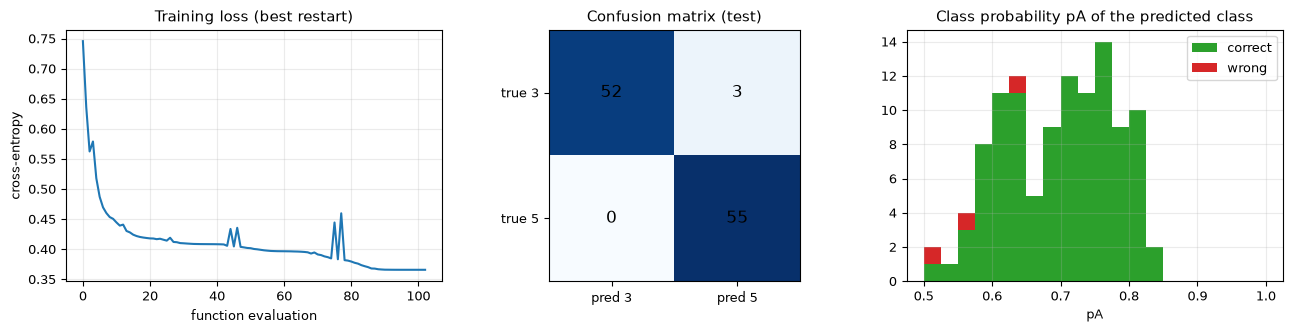

wall-clock for training + baselines: 184s


In [14]:
# ---- training of the quantum classifier (and the classical baselines on exactly the same inputs) ----
def make_split(seed):
    a, b = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    a2, v = train_test_split(a, test_size=VAL_SIZE, stratify=y[a], random_state=seed)
    return a2, v, b

def cross_entropy(theta, Xc, yy):
    """Loss and exact gradient. P(class 1) = 1 - y0.  # CHOICE: cross-entropy, trained with L-BFGS-B on the exact simulator."""
    y0, _ = y0_and_grad(theta, Xc, np.zeros(Xc.shape[1]))
    p1 = np.clip(1 - y0, 1e-9, 1 - 1e-9)
    L = -np.mean(yy * np.log(p1) + (1 - yy) * np.log(1 - p1))
    dL_dy0 = (yy / p1 - (1 - yy) / (1 - p1)) / len(yy)
    return L, y0_and_grad(theta, Xc, dL_dy0)[1]

def train_quantum(idx_fit, idx_sel, seed, restarts=TRAIN_RESTARTS, maxiter=TRAIN_MAXITER):
    """Several random restarts on the fitting split; the restart with the lowest VALIDATION loss is kept."""
    best, hist_best = None, None
    for r in range(restarts):
        th0 = np.random.default_rng(seed * 100 + r).uniform(-np.pi, np.pi, N_PARAMS)
        hist = []
        def fg(th):
            L, g = cross_entropy(th, X_amp[idx_fit].T, y[idx_fit])
            hist.append(L)
            return L, g
        res = optimize.minimize(fg, th0, jac=True, method="L-BFGS-B", options=dict(maxiter=maxiter))
        vloss = cross_entropy(res.x, X_amp[idx_sel].T, y[idx_sel])[0]
        if best is None or vloss < best[1]:
            best, hist_best = (res.x, vloss), hist
    return best[0], hist_best

def predict_q(theta, Xrows):
    y0, _ = y0_and_grad(theta, Xrows.T, np.zeros(len(Xrows)))
    return y0, (y0 < 0.5).astype(int)          # class 1 when P(qubit 0 = 0) < 1/2

rows, models = [], {}
t0 = time.time()
for sd in SEEDS_ACC:
    i_fit, i_val, i_te = make_split(sd)
    t1 = time.time()
    theta, hist = train_quantum(i_fit, i_val, sd)
    t_q = time.time() - t1
    y0, pred = predict_q(theta, X_amp[i_te])
    row = {"seed": sd, "QNN (6 qubits, 24 params)": accuracy_score(y[i_te], pred)}
    for name, clf in [("SVC rbf", SVC(kernel="rbf", C=10, gamma="scale", random_state=sd)),
                      ("Random forest", RandomForestClassifier(n_estimators=200, random_state=sd, n_jobs=1)),
                      ("Logistic regression", LogisticRegression(max_iter=2000, random_state=sd))]:
        clf.fit(X_amp[i_fit], y[i_fit])
        row[name] = accuracy_score(y[i_te], clf.predict(X_amp[i_te]))
    rows.append(row); models[sd] = dict(theta=theta, hist=hist, split=(i_fit, i_val, i_te), t_train=t_q)
    print(f"seed {sd}: quantum test accuracy {row['QNN (6 qubits, 24 params)']:.4f}  (training {t_q:.0f}s)", flush=True)
acc_tab = pd.DataFrame(rows).set_index("seed")
print("\nTest accuracy per seed (classical baselines use exactly the same 64-dimensional unit vectors):")
display_df = acc_tab.round(4)
print(display_df.to_string())
print("\nmean +- std over seeds:")
print((acc_tab.mean().round(4).astype(str) + " +- " + acc_tab.std(ddof=0).round(4).astype(str)).to_string())

# ---- the model used for every analysis below: seed SEED ----
theta_star = models[SEED]["theta"]
i_fit, i_val, i_te = models[SEED]["split"]
assert set(i_te) == set(idx_te)                           # same test split as in the data section
y0_te, pred_te = predict_q(theta_star, X_amp[i_te])
conf_te = np.maximum(y0_te, 1 - y0_te)
print(f"\nmain model (seed {SEED}): test accuracy {accuracy_score(y[i_te], pred_te):.4f}, "
      f"median confidence pA = {np.median(conf_te):.3f}, 10-90% range {np.percentile(conf_te, [10, 90]).round(3)}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(models[SEED]["hist"]); ax[0].set_title("Training loss (best restart)"); ax[0].set_xlabel("function evaluation"); ax[0].set_ylabel("cross-entropy")
cmx = confusion_matrix(y[i_te], pred_te)
ax[1].imshow(cmx, cmap="Blues"); ax[1].grid(False)
for (a_, b_), v_ in np.ndenumerate(cmx):
    ax[1].text(b_, a_, int(v_), ha="center", va="center", fontsize=12)
ax[1].set_xticks([0, 1]); ax[1].set_yticks([0, 1])
ax[1].set_xticklabels([f"pred {DIGIT_PAIR[0]}", f"pred {DIGIT_PAIR[1]}"]); ax[1].set_yticklabels([f"true {DIGIT_PAIR[0]}", f"true {DIGIT_PAIR[1]}"])
ax[1].set_title("Confusion matrix (test)")
ax[2].hist([conf_te[pred_te == y[i_te]], conf_te[pred_te != y[i_te]]], bins=np.linspace(0.5, 1, 21), stacked=True,
           label=["correct", "wrong"], color=["tab:green", "tab:red"])
ax[2].set_title("Class probability pA of the predicted class"); ax[2].set_xlabel("pA"); ax[2].legend()
plt.tight_layout(); plt.show()
print(f"wall-clock for training + baselines: {time.time() - t0:.0f}s")

## Quantum Circuit Architecture

Three circuits are executed in this notebook and each is drawn below from the object that is run (nothing here is an
illustration): (1) the 6-qubit classifier of Part B with its trained parameters (amplitude encoding, `RealAmplitudes`, read-out of
qubit 0); (2) the one-qubit circuit of the paper's toy classifier (`Pi_{theta,phi}`) used in Part A; (3) the Part B classifier
behind the global depolarising channel `E_p` of Section 6, realised on 19 qubits by purification (a coin qubit and six Bell pairs: 6 + 6 + 6 + 1 qubits). For each, the qubit count, depth and
number of trainable parameters are printed, and an assertion ties the drawn circuit to the numbers used elsewhere. The paper
omits all circuit details (it works with abstract channels and POVMs), so the encoding, ansatz depth and read-out qubit are
assumptions, marked `# CHOICE` in the code.

Architecture 1 - amplitude encoding + RealAmplitudes(6, reps=3) + measurement of qubit 0 (circuit as executed, test image #0)


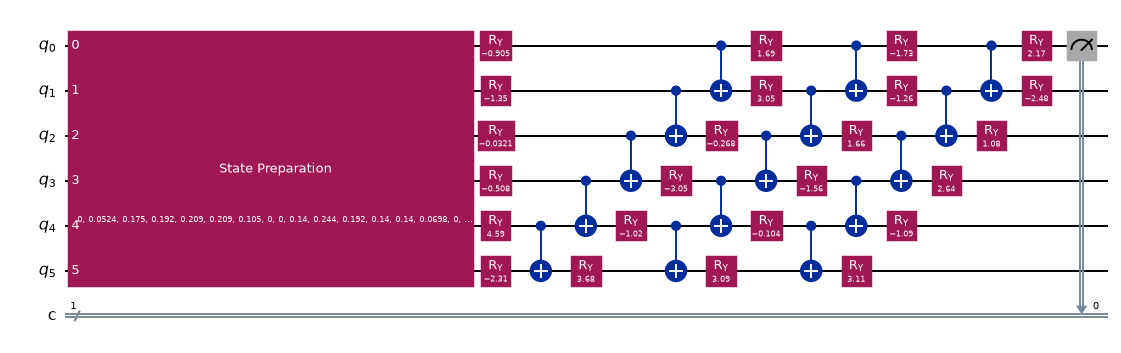

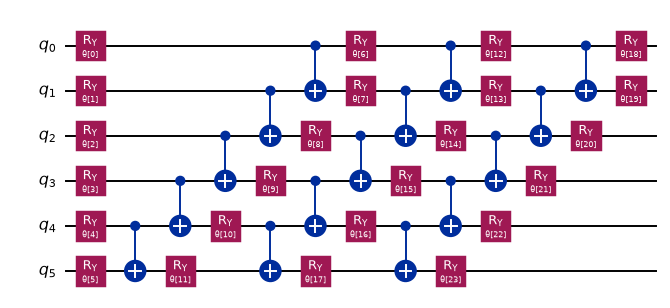

qubits                        : 6  (classical bits: 1)
depth of the drawn circuit    : 15  (StatePreparation counted as one block)
depth of the ansatz alone     : 13  (4 RY layers, 3 CX ladders)
depth after full decomposition: 125  into {'u': 87, 'cx': 72, 'measure': 1}
trainable parameters          : 24  (the 64 amplitudes of the encoded image are data, not parameters)
assumptions (the paper gives no circuit): amplitude encoding of the 8x8 image, RealAmplitudes ansatz with 3 repetitions,
class 0 <-> qubit 0 reads |0>, class 1 <-> qubit 0 reads |1>.



Architecture 2 - single-qubit toy classifier {Pi_{theta,phi}, 1 - Pi_{theta,phi}}, input rho (theta0 = pi/3, phi0 = pi/6)


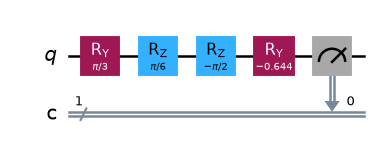

qubits 1, depth 5, trainable parameters 0 (theta = 2 arccos sqrt(0.9) and phi are fixed constants of the example)
OK: P(outcome 0) of this circuit == |<psi_{theta,phi}|input>|^2 = y_+ used in Part A (3 input states)

Architecture 3 - encoding, depolarising channel E_p (p = 0.3, purified with a coin qubit and Bell pairs), ansatz; read-out of data qubit 0


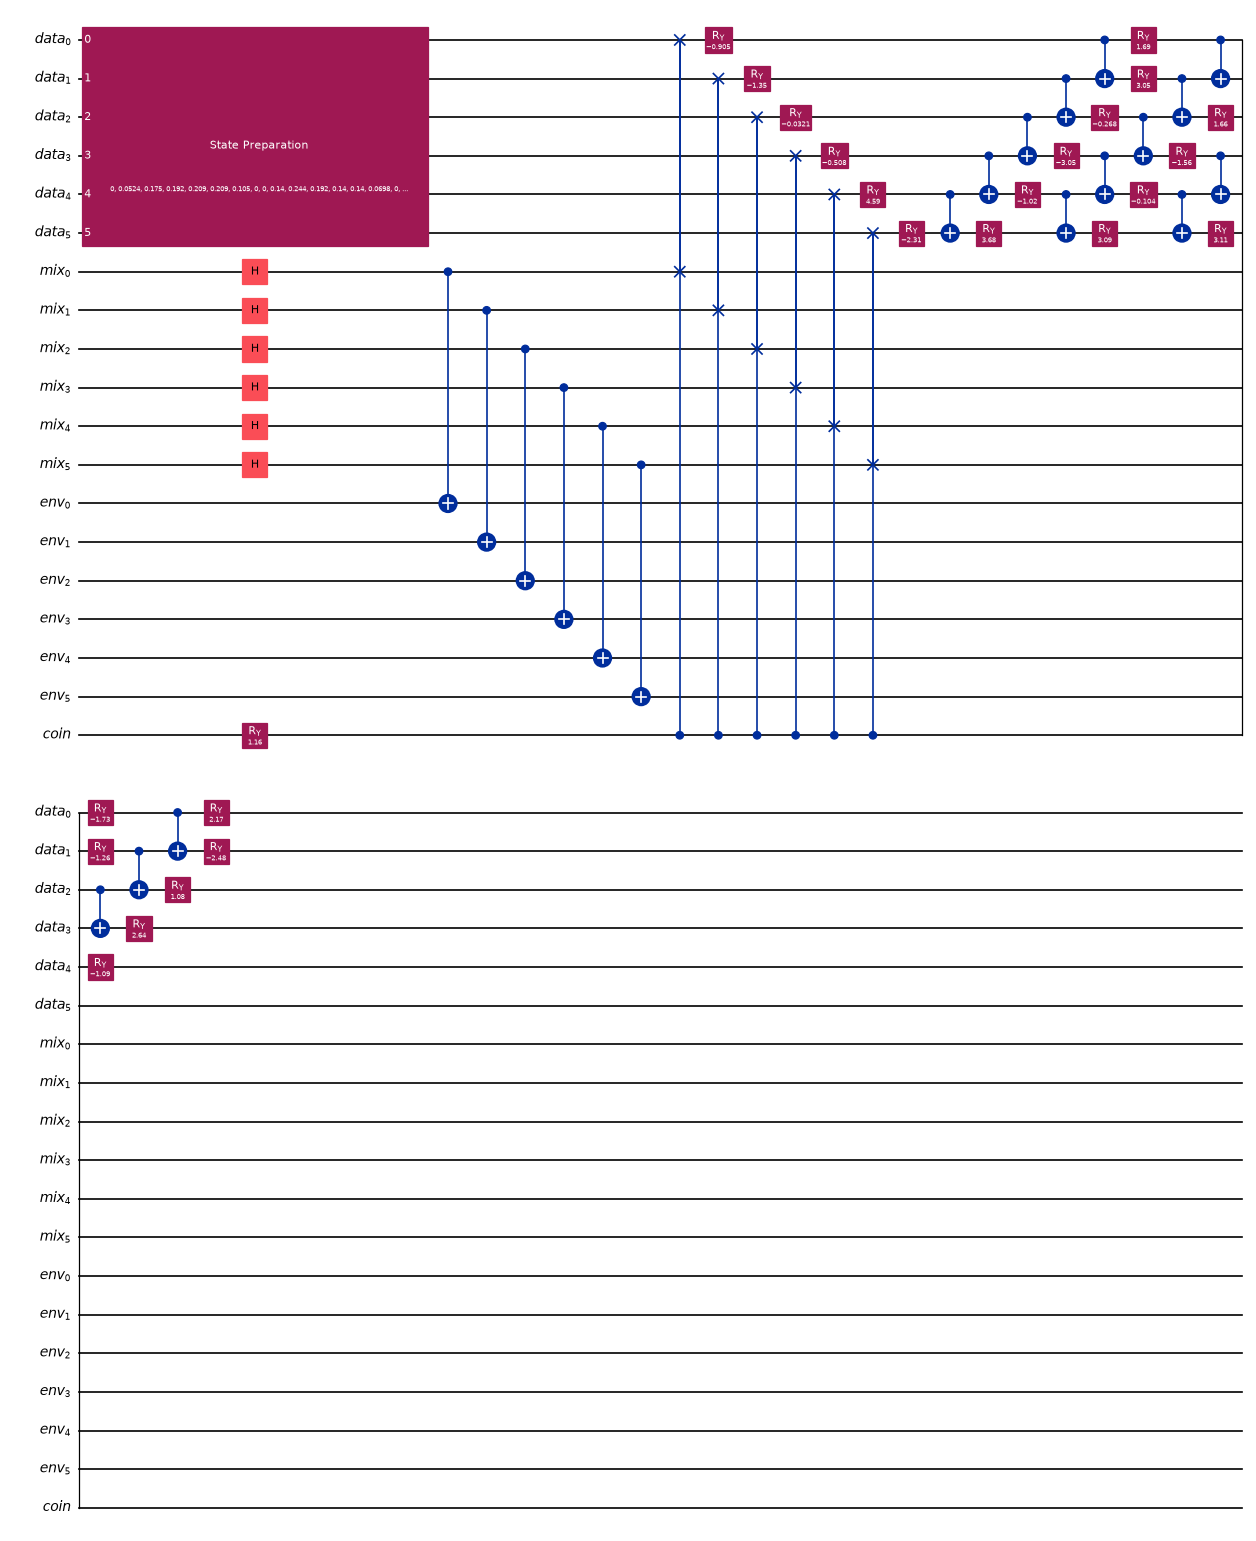

19-qubit circuit P(data qubit 0 = 0) = 0.3866265807   formula (1 - p) y0 + p/2 = 0.3866265807
qubits 19, depth 21 (state preparation counted as one block), trainable parameters 24


In [15]:
from IPython.display import display

# ===== Architecture 1: the 6-qubit classifier executed on the real digit images (trained parameters) =====
x_demo = X_amp[i_te[0]]
qc_cls = classifier_circuit(x_demo, theta_star)
print("Architecture 1 - amplitude encoding + RealAmplitudes(6, reps=3) + measurement of qubit 0 (circuit as executed, test image #0)")
display(qc_cls.draw("mpl", fold=30, scale=0.7))
display(ANSATZ.draw("mpl", fold=30, scale=0.7))          # the same ansatz with its symbolic parameters theta[0..23]
basis = ["u", "cx"]
qc_tr = transpile(qc_cls, basis_gates=basis, optimization_level=0, seed_transpiler=SEED)
qc_ans_tr = transpile(ANSATZ.assign_parameters(theta_star), basis_gates=basis, optimization_level=0, seed_transpiler=SEED)
print(f"qubits                        : {qc_cls.num_qubits}  (classical bits: {qc_cls.num_clbits})")
print(f"depth of the drawn circuit    : {qc_cls.depth()}  (StatePreparation counted as one block)")
print(f"depth of the ansatz alone     : {ANSATZ.depth()}  (4 RY layers, 3 CX ladders)")
print(f"depth after full decomposition: {qc_tr.depth()}  into {dict(qc_tr.count_ops())}")
print(f"trainable parameters          : {N_PARAMS}  (the 64 amplitudes of the encoded image are data, not parameters)")
print("assumptions (the paper gives no circuit): amplitude encoding of the 8x8 image, RealAmplitudes ansatz with 3 repetitions,")
print("class 0 <-> qubit 0 reads |0>, class 1 <-> qubit 0 reads |1>.")
assert np.isclose(Statevector.from_instruction(classifier_circuit(x_demo, theta_star, measure=False)).probabilities([0])[0],
                  y0_and_grad(theta_star, x_demo[:, None], np.zeros(1))[0][0], atol=1e-12)
assert qc_cls.num_qubits == N_QUBITS and qc_ans_tr.depth() >= ANSATZ.depth()

# ===== Architecture 2: the single-qubit classifier of the paper's toy example (Eq. 34) =====
def toy_circuit(th_state, ph_state, th_cls=TH_C, ph_cls=np.pi / 2):
    """Prepare |psi_{th,ph}> = Rz(ph) Ry(th)|0> (up to a global phase), rotate with the inverse of the classifier state, measure."""
    qc = QuantumCircuit(1, 1)
    qc.ry(th_state, 0); qc.rz(ph_state, 0)                       # input state rho (or sigma = |0> for th = 0)
    qc.rz(-ph_cls, 0); qc.ry(-th_cls, 0)                         # U^dagger: maps |psi_{theta,phi}> to |0>
    qc.measure(0, 0)
    return qc
qc_toy = toy_circuit(TH0, PH0)
print("\nArchitecture 2 - single-qubit toy classifier {Pi_{theta,phi}, 1 - Pi_{theta,phi}}, input rho (theta0 = pi/3, phi0 = pi/6)")
display(qc_toy.draw("mpl", scale=0.9))
print(f"qubits {qc_toy.num_qubits}, depth {qc_toy.depth()}, trainable parameters 0 (theta = 2 arccos sqrt(0.9) and phi are fixed constants of the example)")
for (a_, b_) in [(0.0, 0.0), (TH0, PH0), (1.3, 2.2)]:
    y_circ = Statevector.from_instruction(toy_circuit(a_, b_).remove_final_measurements(inplace=False)).probabilities([0])[0]
    assert np.isclose(y_circ, y_plus(proj(ket(a_, b_))), atol=1e-12)
print("OK: P(outcome 0) of this circuit == |<psi_{theta,phi}|input>|^2 = y_+ used in Part A (3 input states)")

# ===== Architecture 3: the same classifier behind the depolarising 'smoothing' channel E_p of Eq. (41) =====
# E_p(x) = (1-p) x + p 1/d is realised as a real circuit by purification (19 qubits): a coin qubit with P(1) = p controls a SWAP of every
# data qubit with one half of a Bell pair whose other half is never touched, so with probability p the data qubits are replaced by a
# maximally mixed state.  (Qiskit's own depolarizing_error needs 4096 Pauli circuits on 6 qubits; it is used for n = 1, 2 in Section 6.)
from qiskit import QuantumRegister
P_DEMO = 0.3
def depolarised_classifier_circuit(x, theta, p):
    n = N_QUBITS
    data, mix, env, coin = QuantumRegister(n, "data"), QuantumRegister(n, "mix"), QuantumRegister(n, "env"), QuantumRegister(1, "coin")
    qc = QuantumCircuit(data, mix, env, coin)
    qc.append(StatePreparation(np.asarray(x, float) / np.linalg.norm(x)), data)
    for i in range(n):
        qc.h(mix[i]); qc.cx(mix[i], env[i])                    # Bell pairs
    qc.ry(2 * np.arcsin(np.sqrt(p)), coin[0])                  # P(coin = 1) = p
    for i in range(n):
        qc.cswap(coin[0], data[i], mix[i])
    qc.compose(ANSATZ.assign_parameters(theta), qubits=list(data), inplace=True)
    return qc
qc_dep = depolarised_classifier_circuit(x_demo, theta_star, P_DEMO)
print("\nArchitecture 3 - encoding, depolarising channel E_p (p = 0.3, purified with a coin qubit and Bell pairs), ansatz; read-out of data qubit 0")
display(qc_dep.draw("mpl", fold=30, scale=0.6))
y_clean_demo = y0_and_grad(theta_star, x_demo[:, None], np.zeros(1))[0][0]
p0_dep = Statevector.from_instruction(qc_dep).probabilities([0])[0]
print(f"19-qubit circuit P(data qubit 0 = 0) = {p0_dep:.10f}   formula (1 - p) y0 + p/2 = {(1 - P_DEMO) * y_clean_demo + P_DEMO / 2:.10f}")
assert np.isclose(p0_dep, (1 - P_DEMO) * y_clean_demo + P_DEMO / 2, atol=1e-9)
print(f"qubits {qc_dep.num_qubits}, depth {qc_dep.depth()} (state preparation counted as one block), trainable parameters {N_PARAMS}")

## 8. Certified accuracy of the trained classifier (Protocol 1, Hoeffding, classical baseline)

For every test image the class probability `pA` of the predicted class gives, through Eq. (14), the largest infidelity
`eps = 1 - F` that is certified: `eps_QHT = 1/2 - sqrt(pA(1 - pA))`. The Holder bound of Lemma 2 certifies `eps_H = (pA - 1/2)^2` for
pure states. The *certified accuracy* at budget `eps` (Eq. 35) is the fraction of test images that are classified correctly and
have a certified infidelity larger than `eps`.

* **Protocol 1** estimates `pA` from `N` executions of the circuit: `p_hat = n_kA / N - sqrt(-ln(alpha) / (2N))` (Hoeffding). Five states are
  run with Aer's shot simulator on the real transpiled circuit to check that the sampling distribution is the predicted one;
  a coverage experiment checks that `p_hat` falls below the true `pA` in at least a fraction `1 - alpha` of the repetitions.
* **Classical baseline.** Randomised smoothing (Cohen et al.) on the *same* 64-dimensional unit vectors: a logistic regression
  trained on Gaussian-perturbed copies is queried on `n` noisy copies of the image, a one-sided Clopper-Pearson bound gives
  `pA_low`, and the certified l2 radius is `R = sigma Phi^{-1}(pA_low)`. For unit vectors `||x - x'|| < R` is the same as
  `F > (1 - R^2/2)^2`, so both certificates are plotted on one axis. (A caveat for the comparison: the classical certificate
  only covers real perturbations of the classical vector, the quantum one covers every pure or mixed state.)

110 test states certified; QNN test accuracy on them 0.973; pA: median 0.703, min 0.509, max 0.829


Protocol 1 with N = 2000 executions and Hoeffding alpha = 0.001: abstains on 2.7% of the states; the sampled class agrees with the exact class on 100.0%


Aer shot runs of the transpiled classifier circuit (Protocol 1, steps 1-3):
 state  exact_y0  aer_freq_0  z_score  class_aer  class_exact  eps_cert_aer  eps_cert_exact
     0    0.3380      0.3455     0.71          1            1        0.0129          0.0270
     1    0.7293      0.7205    -0.88          0            0        0.0331          0.0557
     2    0.3913      0.4015     0.93          1            1        0.0033          0.0120
     3    0.8165      0.8075    -1.03          0            0        0.0766          0.1129
     4    0.3547      0.3405    -1.33          1            1        0.0141          0.0216



Hoeffding coverage: fraction of repetitions in which the lower bound p_hat_A is NOT below the true class probability (must be <= alpha):
 alpha    N  repetitions  violation_rate  bound_holds
 0.001  100      2200000        0.000056         True
 0.001 2000      2200000        0.000035         True
 0.200  100      2200000        0.028144         True
 0.200 2000      2200000        0.024199         True



validation scores (mean certified radius x correctness) per noise level: {0.05: 0.096, 0.1: 0.148, 0.2: 0.161, 0.3: 0.144, 0.4: 0.13} -> sigma = 0.2


classical base classifier (logistic regression trained with N(0, 0.2^2) noise): clean test accuracy 0.9818, accuracy under noise 0.8273


classical smoothed classifier: accuracy 0.982, median certified l2 radius 0.225 (= infidelity 0.0501), maximal possible radius with 5000 draws = 0.599

Certified accuracy at infidelity budget eps (fraction of test states that are correct AND certified):
 eps=1-F  QHT exact pA  QHT Protocol 1  Holder (Lemma 2)  classical smoothing
    0.00         0.973           0.955             0.973                0.982
    0.02         0.700           0.573             0.700                0.818
    0.04         0.536           0.364             0.527                0.618
    0.06         0.355           0.191             0.355                0.391
    0.10         0.109           0.000             0.027                0.091
    0.20         0.000           0.000             0.000                0.000


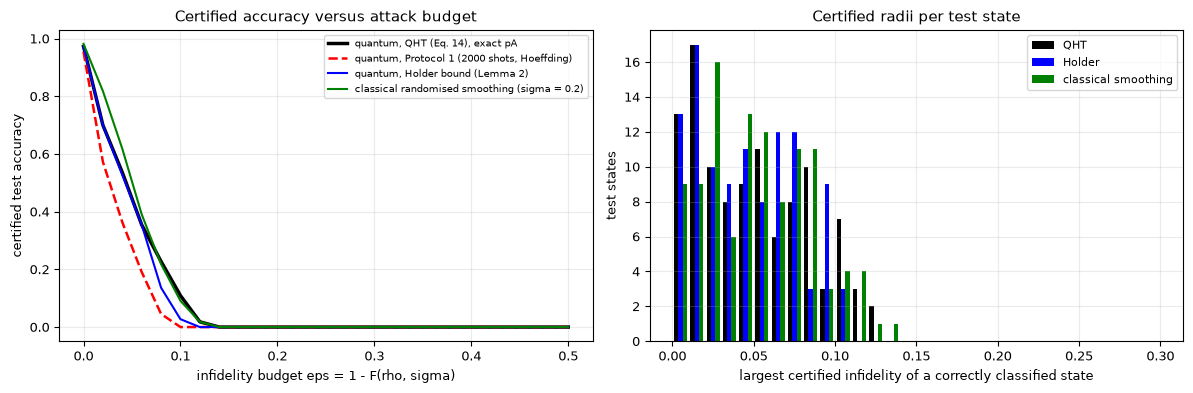

QHT certifies at least as many states as the Holder bound at every eps: True;  QHT >= classical smoothing at every eps: False
largest eps with positive certified accuracy: QHT 0.120, Holder 0.100, classical 0.120


In [16]:
# ---- certified accuracy of the trained quantum classifier (Eq. 35) and its classical randomised-smoothing baseline ----
N_EVAL = min(N_CERT, len(i_te))
sel = np.arange(N_EVAL)                                     # first N_EVAL states of the (randomly ordered) test split
X_ev, y_ev = X_amp[i_te][sel], y[i_te][sel]
y0_ev, pred_ev = predict_q(theta_star, X_ev)
pA_ev = np.maximum(y0_ev, 1 - y0_ev)
correct_ev = pred_ev == y_ev
print(f"{N_EVAL} test states certified; QNN test accuracy on them {correct_ev.mean():.3f}; pA: median {np.median(pA_ev):.3f}, min {pA_ev.min():.3f}, max {pA_ev.max():.3f}")

# per-state largest infidelity eps = 1 - F that is certified
eps_qht = 1 - r_fid(pA_ev)                                  # Eq. (14):  F > 1/2 + sqrt(pA (1 - pA))
eps_holder = (pA_ev - 0.5) ** 2                             # Lemma 2 for pure states: sqrt(1 - F) < (2 pA - 1)/2
def cert_acc(eps_cert, eps_grid=EPS_GRID):
    return np.array([np.mean(correct_ev & (eps_cert > e)) for e in eps_grid])

# ---- Protocol 1 with a finite number of circuit executions (Hoeffding) ----
def protocol1_from_counts(n0, N, alpha):
    """counts of outcome 0 -> (predicted class, certified infidelity eps) or abstain (eps = -1).  Steps 2-3 of Protocol 1."""
    n_hi = max(n0, N - n0)
    pa_hat = n_hi / N - np.sqrt(-np.log(alpha) / (2 * N))
    k = 0 if n0 >= N - n0 else 1
    return (k, 1 - float(r_fid(pa_hat))) if pa_hat > 0.5 else (k, -1.0)

rs_ = np.random.default_rng(SEED + 7)
n0_ev = rs_.binomial(SHOTS_PROTOCOL, y0_ev)                  # outcome counts of N executions of the real circuit (validated with Aer below)
p1 = [protocol1_from_counts(int(n0), SHOTS_PROTOCOL, HOEFFDING_ALPHA) for n0 in n0_ev]
pred_p1 = np.array([a for a, _ in p1]); eps_p1 = np.array([b for _, b in p1])
correct_p1 = pred_p1 == y_ev
cert_p1 = np.array([np.mean(correct_p1 & (eps_p1 > e)) for e in EPS_GRID])
print(f"Protocol 1 with N = {SHOTS_PROTOCOL} executions and Hoeffding alpha = {HOEFFDING_ALPHA}: abstains on {np.mean(eps_p1 < 0):.1%} of the states; "
      f"the sampled class agrees with the exact class on {np.mean(pred_p1 == pred_ev):.1%}")

# --- the same protocol on the REAL circuit with Aer shots (5 states) ---
sim_shots = AerSimulator(seed_simulator=SEED)
rows_aer = []
for j in range(5):
    qc_j = classifier_circuit(X_ev[j], theta_star)
    cnt = sim_shots.run(transpile(qc_j, sim_shots, seed_transpiler=SEED), shots=SHOTS_PROTOCOL).result().get_counts()   # real transpiled circuit
    n0 = cnt.get("0", 0)
    k_j, e_j = protocol1_from_counts(n0, SHOTS_PROTOCOL, HOEFFDING_ALPHA)
    z = (n0 - SHOTS_PROTOCOL * y0_ev[j]) / np.sqrt(SHOTS_PROTOCOL * y0_ev[j] * (1 - y0_ev[j]))
    rows_aer.append(dict(state=j, exact_y0=round(y0_ev[j], 4), aer_freq_0=round(n0 / SHOTS_PROTOCOL, 4), z_score=round(z, 2),
                         class_aer=k_j, class_exact=pred_ev[j], eps_cert_aer=round(e_j, 4), eps_cert_exact=round(eps_qht[j], 4)))
    assert abs(z) < 4.5
print("Aer shot runs of the transpiled classifier circuit (Protocol 1, steps 1-3):")
print(pd.DataFrame(rows_aer).to_string(index=False))

# --- coverage of the Hoeffding bound: how often does p_hat_A exceed the true class probability? ---
cov_rows = []
for alpha in [HOEFFDING_ALPHA, 0.2]:
    for N in [100, SHOTS_PROTOCOL]:
        viol = tot = 0
        for j in range(N_EVAL):
            n0s = rs_.binomial(N, y0_ev[j], size=COVERAGE_REPS)
            for n0 in np.unique(n0s):
                k_s = 0 if n0 >= N - n0 else 1
                pa_hat = max(n0, N - n0) / N - np.sqrt(-np.log(alpha) / (2 * N))
                p_true = y0_ev[j] if k_s == 0 else 1 - y0_ev[j]
                m = int(np.sum(n0s == n0))
                tot += m; viol += m * int(pa_hat > p_true)
        cov_rows.append(dict(alpha=alpha, N=N, repetitions=tot, violation_rate=viol / tot, bound_holds=viol / tot <= alpha))
cov = pd.DataFrame(cov_rows)
print("\nHoeffding coverage: fraction of repetitions in which the lower bound p_hat_A is NOT below the true class probability (must be <= alpha):")
print(cov.to_string(index=False))

# ---- classical baseline: randomised smoothing (Cohen et al. 2019) on exactly the same unit vectors ----
Xfit, yfit = X_amp[i_fit], y[i_fit]
aug = 20
rs2 = np.random.default_rng(SEED + 11)
alpha_rs = HOEFFDING_ALPHA

def rs_train(sigma):
    """Base classifier trained on Gaussian-augmented copies of the training vectors (needed for randomised smoothing)."""
    Xn = np.repeat(Xfit, aug, 0) + rs2.normal(0, sigma, (len(Xfit) * aug, 64))
    return LogisticRegression(max_iter=3000, C=10.0, random_state=SEED).fit(Xn, np.repeat(yfit, aug))

def rs_certify(base_clf, sigma, Xs, n_draws):
    """Cohen et al. CERTIFY: majority vote of n_draws noisy copies, Clopper-Pearson lower bound on pA, R = sigma Phi^{-1}(pA_lower)."""
    R, pred = np.zeros(len(Xs)), np.zeros(len(Xs), int)
    for j in range(len(Xs)):
        k1 = int(base_clf.predict(Xs[j] + rs2.normal(0, sigma, (n_draws, 64))).sum())
        kcnt = max(k1, n_draws - k1)
        pred[j] = 1 if k1 > n_draws - k1 else 0
        pa_low = stats.beta.ppf(alpha_rs, kcnt, n_draws - kcnt + 1)             # one-sided Clopper-Pearson lower bound
        R[j] = sigma * stats.norm.ppf(pa_low) if pa_low > 0.5 else 0.0          # pB = 1 - pA
    return R, pred

# CHOICE of the noise level on the VALIDATION split only: the sigma that maximises the mean certified radius of correct predictions
val_scores = {}
for sg in SIGMA_RS_GRID:
    bc = rs_train(sg)
    Rv, pv = rs_certify(bc, sg, X_amp[i_val][:40], 300)
    val_scores[sg] = float(np.mean(Rv * (pv == y[i_val][:40])))
SIGMA_RS = max(val_scores, key=val_scores.get)
print(f"\nvalidation scores (mean certified radius x correctness) per noise level: { {k: round(v, 3) for k, v in val_scores.items()} } -> sigma = {SIGMA_RS}")
base = rs_train(SIGMA_RS)
print(f"classical base classifier (logistic regression trained with N(0, {SIGMA_RS}^2) noise): clean test accuracy "
      f"{accuracy_score(y[i_te], base.predict(X_amp[i_te])):.4f}, accuracy under noise "
      f"{accuracy_score(y[i_te], base.predict(X_amp[i_te] + rs2.normal(0, SIGMA_RS, (len(i_te), 64)))):.4f}")
R_rs, pred_rs = rs_certify(base, SIGMA_RS, X_ev, N_RS_SAMPLES)
# map the l2 radius R (unit vectors, ||x - x'|| < R) to the quantum figure of merit: F = (1 - R^2/2)^2 for unit vectors
eps_rs = 1 - np.clip(1 - R_rs ** 2 / 2, 0, 1) ** 2
correct_rs = pred_rs == y_ev
cert_rs = np.array([np.mean(correct_rs & (eps_rs > e)) for e in EPS_GRID])
print(f"classical smoothed classifier: accuracy {correct_rs.mean():.3f}, median certified l2 radius {np.median(R_rs):.3f} "
      f"(= infidelity {np.median(eps_rs):.4f}), maximal possible radius with {N_RS_SAMPLES} draws = {SIGMA_RS * stats.norm.ppf(stats.beta.ppf(alpha_rs, N_RS_SAMPLES, 1)):.3f}")

cert_qht, cert_hol = cert_acc(eps_qht), cert_acc(eps_holder)
tab_c = pd.DataFrame({"eps=1-F": EPS_GRID, "QHT exact pA": cert_qht, "QHT Protocol 1": cert_p1, "Holder (Lemma 2)": cert_hol, "classical smoothing": cert_rs})
sel_rows = tab_c[tab_c["eps=1-F"].isin([0.0, 0.02, 0.04, 0.06, 0.1, 0.2])].round(3)
print("\nCertified accuracy at infidelity budget eps (fraction of test states that are correct AND certified):")
print(sel_rows.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(EPS_GRID, cert_qht, "k-", lw=2.5, label="quantum, QHT (Eq. 14), exact pA")
ax[0].plot(EPS_GRID, cert_p1, "r--", lw=1.8, label=f"quantum, Protocol 1 ({SHOTS_PROTOCOL} shots, Hoeffding)")
ax[0].plot(EPS_GRID, cert_hol, "b-", label="quantum, Holder bound (Lemma 2)")
ax[0].plot(EPS_GRID, cert_rs, "g-", label=f"classical randomised smoothing (sigma = {SIGMA_RS})")
ax[0].set_xlabel("infidelity budget eps = 1 - F(rho, sigma)"); ax[0].set_ylabel("certified test accuracy"); ax[0].set_title("Certified accuracy versus attack budget"); ax[0].legend(fontsize=7)
ax[1].hist([eps_qht[correct_ev], eps_holder[correct_ev], eps_rs[correct_rs]], bins=np.linspace(0, 0.3, 31), label=["QHT", "Holder", "classical smoothing"], color=["k", "b", "g"])
ax[1].set_xlabel("largest certified infidelity of a correctly classified state"); ax[1].set_ylabel("test states"); ax[1].set_title("Certified radii per test state"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
dom = bool(np.all(cert_qht >= cert_hol - 1e-12))
print(f"QHT certifies at least as many states as the Holder bound at every eps: {dom};  QHT >= classical smoothing at every eps: {bool(np.all(cert_qht >= cert_rs - 1e-12))}")
print(f"largest eps with positive certified accuracy: QHT {EPS_GRID[cert_qht > 0].max():.3f}, Holder {EPS_GRID[cert_hol > 0].max():.3f}, classical {EPS_GRID[cert_rs > 0].max() if (cert_rs > 0).any() else 0:.3f}")

## 9. How good is the certificate? Real attacks on the trained classifier

A certificate is only useful if it is both *sound* (no attack succeeds inside it) and reasonably *tight* (attacks succeed soon
outside it). Three adversaries are used, all allowed to replace `sigma` by a state at fidelity at least `1 - eps`:

1. **The exact optimal adversary.** For a fixed classifier `Lambda` and pure `sigma`, the smallest class probability that any
   state `rho` with `<sigma|rho|sigma> >= r` can leave is `max_{mu >= 0} lambda_min(Lambda - mu |sigma><sigma|) + mu r` (Lagrange
   dual of a semidefinite programme; pure *and* mixed `rho` are covered). The cell computes it with the full 64 x 64 eigenvalue problem
   on a few states and then with an exact 2 x 2 reduction (the only part of the space that matters is spanned by
   `Lambda|sigma>` and `(1 - Lambda)|sigma>`), asserts that the two agree, and bisects on `eps` to find the exact flipping radius.
2. **A gradient attack** that does not use this structure: a majorise-minimise projected gradient method on the sphere of pure states at
   fidelity exactly `1 - eps` (monotone decrease of the class probability), once over complex states and once restricted to real
   amplitudes (the kind of perturbation that an edit of the image would produce), with a bisection on `eps` per image.
3. **Random orthogonal perturbations** at 1.5 times the certified radius, the non-adversarial reference.

OK: exact worst-case class probability from the 64-dim dual == the 2x2 reduction (4 states x 3 radii)


exact optimal adversary vs QHT certificate: max |eps_exact - eps_QHT| = 9.09e-13 over 110 states
                                   vs Holder: median eps_Holder / eps_exact = 0.957



MM attack (600 iterations, 18 bisection steps, 102s): smallest eps that flips the prediction
           statistic  QHT certificate  exact optimal adversary  complex-state attack  real-amplitude attack  Holder certificate
              median          0.04318                  0.04318               0.04318                0.04318             0.04131
                mean          0.04813                  0.04813               0.04813                0.04813             0.04465
  max |attack - QHT|              NaN                      NaN               0.00000                0.00000                 NaN
max |attack - exact|              NaN                      NaN               0.00000                0.00000                 NaN

soundness: attacks that flip a prediction INSIDE the certified region: QHT 0, Holder 0  (tolerance 0.002)
tightness: largest distance between the best attack and the QHT radius = 0.0000 in infidelity


random orthogonal perturbations at eps = 1.5 x QHT radius flip the prediction in 0.00% of the draws (the worst-case adversary succeeds in 100% of the states at that budget)


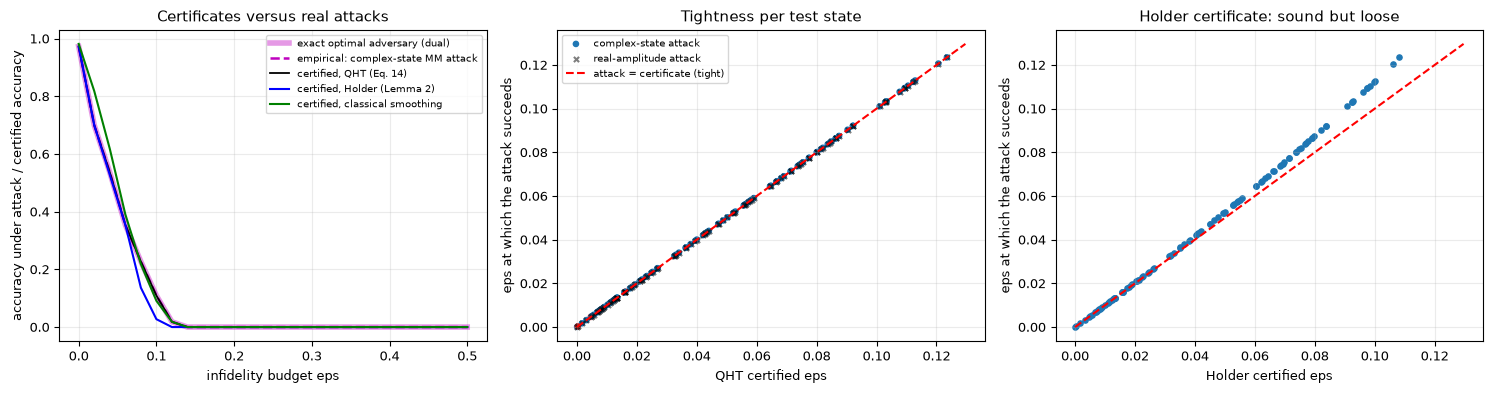

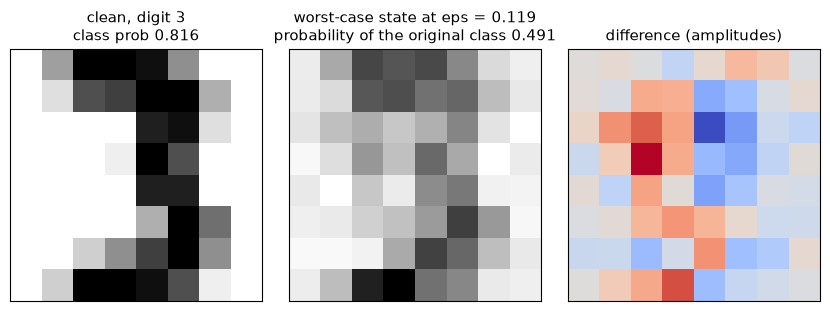

In [17]:
# ---- how good is the certificate? attack the trained quantum classifier with the strongest adversaries we can build ----
# The adversary may replace the input state sigma by ANY state rho with fidelity F(rho, sigma) >= 1 - eps (pure or mixed, as in Theorem 3).
L0 = povm_class0(theta_star)                      # effect of class 0 (rank-32 projector), class 1 has 1 - L0
L1 = np.eye(D) - L0
Lam_of = {0: L0, 1: L1}

# (1) EXACT optimal adversary through the Lagrange dual of  min_rho tr(Lam rho)  s.t.  <s|rho|s> >= r:  max_{mu>=0} lambda_min(Lam - mu |s><s|) + mu r
def golden_max(f, lo, hi, iters=70):
    gr = (np.sqrt(5) - 1) / 2
    x1, x2 = hi - gr * (hi - lo), lo + gr * (hi - lo)
    f1, f2 = f(x1), f(x2)
    for _ in range(iters):
        if f1 < f2:
            lo, x1, f1 = x1, x2, f2; x2 = lo + gr * (hi - lo); f2 = f(x2)
        else:
            hi, x2, f2 = x2, x1, f1; x1 = hi - gr * (hi - lo); f1 = f(x1)
    return max(f1, f2)

def worst_y_full(Lam, s, r):
    """Dual value with the full 64 x 64 eigenvalue problem (the reference)."""
    P = np.outer(s, s)
    return golden_max(lambda mu: np.linalg.eigvalsh(Lam - mu * P)[0] + mu * r, 0.0, 1.0 / max(1 - r, 1e-9))

def worst_y_2d(y, r):
    """Same dual value from the 2 x 2 block spanned by Lam|s> and (1 - Lam)|s>:  lambda_min(mu) = ((1-mu) - sqrt((1-mu)^2 + 4 mu (1-y)))/2."""
    return golden_max(lambda mu: 0.5 * ((1 - mu) - np.sqrt((1 - mu) ** 2 + 4 * mu * (1 - y))) + mu * r, 0.0, 1.0 / max(1 - r, 1e-9))

for j in range(4):
    c = int(pred_ev[j]); s = X_ev[j]; y_c = float(s @ Lam_of[c] @ s)
    for r in (0.95, 0.9, 0.8):
        assert abs(worst_y_full(Lam_of[c], s, r) - worst_y_2d(y_c, r)) < 1e-7
print("OK: exact worst-case class probability from the 64-dim dual == the 2x2 reduction (4 states x 3 radii)")

def eps_exact_from_y(y_c, iters=40):
    """Smallest infidelity eps at which the best adversary pushes the class probability to 1/2 (bisection on the dual)."""
    lo, hi = 0.0, 1.0
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if worst_y_2d(y_c, 1 - mid) > 0.5 else (lo, mid)
    return lo
eps_opt = np.array([eps_exact_from_y(pA_ev[j]) for j in range(N_EVAL)])
print(f"exact optimal adversary vs QHT certificate: max |eps_exact - eps_QHT| = {np.abs(eps_opt - eps_qht).max():.2e} over {N_EVAL} states")
print(f"                                   vs Holder: median eps_Holder / eps_exact = {np.median(eps_holder / eps_opt):.3f}")

# (2) a practical white-box attack: monotone (majorise-minimise) projected gradient descent on the fidelity sphere
def mm_attack_y(sig, Lam, eps, iters, complex_state=True, seed=0):
    """Minimise <phi|Lam|phi> over phi = sqrt(1-eps) |s> + sqrt(eps) |v>, v unit and orthogonal to s (fidelity exactly 1 - eps).
    Each step minimises a linearised, majorising surrogate, so the objective never increases.  sig: (N, 64) real unit vectors, eps: (N,)."""
    rg = np.random.default_rng(seed)
    N = len(sig)
    r = (1 - eps)[:, None]
    C = np.eye(D) - Lam
    c = np.sqrt(r * (1 - r)) * (sig @ Lam)                                   # (N, 64) = sqrt(r(1-r)) Lam s
    def perp(v):
        return v - (np.sum(sig * v, 1, keepdims=True)) * sig
    def norm(v):
        return v / np.maximum(np.linalg.norm(v, axis=1, keepdims=True), 1e-300)
    v = norm(perp(-c).astype(complex))
    if complex_state:
        v = norm(perp(v + 0.3 * (rg.normal(size=v.shape) + 1j * rg.normal(size=v.shape))))
    for _ in range(iters):
        v = norm(perp((1 - r) * (v @ C) - c))
        if not complex_state:
            v = norm(perp(v.real)).astype(complex)
    phi = np.sqrt(r) * sig + np.sqrt(1 - r) * v
    return np.real(np.einsum("ni,ij,nj->n", phi.conj(), Lam, phi)), phi

def attack_threshold(complex_state, bisect=18):
    """Per state: smallest eps at which the MM attack flips the prediction (bisection on eps, vectorised over the states of each class)."""
    thr = np.zeros(N_EVAL)
    for c in (0, 1):
        m = pred_ev == c
        if not m.any():
            continue
        lo, hi = np.zeros(m.sum()), np.ones(m.sum())
        for _ in range(bisect):
            mid = 0.5 * (lo + hi)
            y_adv, _ = mm_attack_y(X_ev[m], Lam_of[c], mid, ATTACK_ITERS, complex_state)
            flipped = y_adv < 0.5
            hi = np.where(flipped, mid, hi); lo = np.where(flipped, lo, mid)
        thr[m] = hi
    return thr
t_att = time.time()
eps_att_c = attack_threshold(True)
eps_att_r = attack_threshold(False)
print(f"\nMM attack ({ATTACK_ITERS} iterations, 18 bisection steps, {time.time() - t_att:.0f}s): smallest eps that flips the prediction")
tab_att = pd.DataFrame({"statistic": ["median", "mean", "max |attack - QHT|", "max |attack - exact|"],
                        "QHT certificate": [np.median(eps_qht), eps_qht.mean(), np.nan, np.nan],
                        "exact optimal adversary": [np.median(eps_opt), eps_opt.mean(), np.nan, np.nan],
                        "complex-state attack": [np.median(eps_att_c), eps_att_c.mean(), np.abs(eps_att_c - eps_qht).max(), np.abs(eps_att_c - eps_opt).max()],
                        "real-amplitude attack": [np.median(eps_att_r), eps_att_r.mean(), np.abs(eps_att_r - eps_qht).max(), np.abs(eps_att_r - eps_opt).max()],
                        "Holder certificate": [np.median(eps_holder), eps_holder.mean(), np.nan, np.nan]}).round(5)
print(tab_att.to_string(index=False))

# (3) soundness and tightness verdicts
tol_s = 2e-3
viol_qht = int(np.sum(eps_att_c < eps_qht - tol_s) + np.sum(eps_att_r < eps_qht - tol_s))
viol_hol = int(np.sum(eps_att_c < eps_holder - tol_s) + np.sum(eps_att_r < eps_holder - tol_s))
gap_t = float(np.max(np.abs(eps_att_c - eps_qht)))
print(f"\nsoundness: attacks that flip a prediction INSIDE the certified region: QHT {viol_qht}, Holder {viol_hol}  (tolerance {tol_s})")
print(f"tightness: largest distance between the best attack and the QHT radius = {gap_t:.4f} in infidelity")

# (4) random perturbations just outside the QHT radius (a non-adversarial 'noise' baseline)
rg3 = np.random.default_rng(SEED + 3)
flip_rand = []
for j in range(N_EVAL):
    s = X_ev[j]; e_ = min(1.5 * eps_qht[j], 1.0); c = int(pred_ev[j])
    v = rg3.normal(size=(300, D)) + 1j * rg3.normal(size=(300, D))
    v = v - (v @ s)[:, None] * s
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    phi = np.sqrt(1 - e_) * s + np.sqrt(e_) * v
    flip_rand.append(np.mean(np.einsum("ni,ij,nj->n", phi.conj(), Lam_of[c], phi).real < 0.5))
print(f"random orthogonal perturbations at eps = 1.5 x QHT radius flip the prediction in {100 * np.mean(flip_rand):.2f}% of the draws "
      "(the worst-case adversary succeeds in 100% of the states at that budget)")

# (5) empirical robust accuracy next to the certified accuracy
rob_c = np.array([np.mean(correct_ev & (eps_att_c > e)) for e in EPS_GRID])
rob_opt = np.array([np.mean(correct_ev & (eps_opt > e)) for e in EPS_GRID])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(EPS_GRID, rob_opt, "m-", lw=4, alpha=0.4, label="exact optimal adversary (dual)")
ax[0].plot(EPS_GRID, rob_c, "m--", lw=1.8, label="empirical: complex-state MM attack")
ax[0].plot(EPS_GRID, cert_qht, "k-", lw=1.3, label="certified, QHT (Eq. 14)")
ax[0].plot(EPS_GRID, cert_hol, "b-", label="certified, Holder (Lemma 2)")
ax[0].plot(EPS_GRID, cert_rs, "g-", label="certified, classical smoothing")
ax[0].set_xlabel("infidelity budget eps"); ax[0].set_ylabel("accuracy under attack / certified accuracy"); ax[0].set_title("Certificates versus real attacks"); ax[0].legend(fontsize=7)
ax[1].scatter(eps_qht, eps_att_c, s=14, c=np.where(correct_ev, "tab:blue", "tab:red"), label="complex-state attack")
ax[1].scatter(eps_qht, eps_att_r, s=14, marker="x", c="k", alpha=0.5, label="real-amplitude attack")
mm_ = max(eps_qht.max(), eps_att_c.max()) * 1.05
ax[1].plot([0, mm_], [0, mm_], "r--", label="attack = certificate (tight)"); ax[1].set_xlabel("QHT certified eps"); ax[1].set_ylabel("eps at which the attack succeeds")
ax[1].set_title("Tightness per test state"); ax[1].legend(fontsize=7)
ax[2].scatter(eps_holder, eps_att_c, s=14, c="tab:blue"); ax[2].plot([0, mm_], [0, mm_], "r--")
ax[2].set_xlabel("Holder certified eps"); ax[2].set_ylabel("eps at which the attack succeeds"); ax[2].set_title("Holder certificate: sound but loose")
plt.tight_layout(); plt.show()

# (6) the worst-case adversarial state of one test image, shown as an image (its real part is a valid 8x8 'picture')
j0 = int(np.argmax(correct_ev & (pA_ev > np.percentile(pA_ev[correct_ev], 60))))
c0 = int(pred_ev[j0]); e0 = float(min(eps_qht[j0] * 1.05, 1.0))
y_adv0, phi0 = mm_attack_y(X_ev[j0:j0 + 1], Lam_of[c0], np.array([e0]), ATTACK_ITERS, complex_state=False)
phi0 = phi0[0].real
fig, ax = plt.subplots(1, 3, figsize=(8.5, 3))
ax[0].imshow(X_ev[j0].reshape(8, 8), cmap="gray_r"); ax[0].set_title(f"clean, digit {DIGIT_PAIR[int(y_ev[j0])]}\nclass prob {pA_ev[j0]:.3f}")
ax[1].imshow(phi0.reshape(8, 8), cmap="gray_r"); ax[1].set_title(f"worst-case state at eps = {e0:.3f}\nprobability of the original class {y_adv0[0]:.3f}")
ax[2].imshow((phi0 - X_ev[j0]).reshape(8, 8), cmap="coolwarm"); ax[2].set_title("difference (amplitudes)")
for a_ in ax:
    a_.set_xticks([]); a_.set_yticks([]); a_.grid(False)
plt.tight_layout(); plt.show()

add_claim("B1", "Part B", "QHT certifies at least as many test states as the Holder bound (QHT bound is the tighter one)", "tighter (Fig. 2, 5)",
          f"certified accuracy QHT >= Holder at every eps: {dom}", "reproduced" if dom else "not reached")
add_claim("B2", "Part B", "certificate is sound against real attacks on a trained 6-qubit classifier", "guaranteed",
          f"{viol_qht} attack successes inside the QHT region ({2 * N_EVAL} attacks)", "reproduced" if viol_qht == 0 else "not reached")
add_claim("B3", "Part B", "the QHT radius is attained by an attack (tightness, Theorem 2) for the trained classifier", "tight (pA + pB = 1)",
          f"max |eps_attack - eps_QHT| = {gap_t:.4f}; Holder is {np.median(eps_holder / eps_opt):.2f}x the exact radius (median)",
          "reproduced" if gap_t < 0.02 else "not reached")

## 10. Protocol 2: was a noisy outcome changed by the noise?

Here the circuit receives a *noisy* encoded state `rho` and we know only that `F(rho, sigma) > 1 - eps` for the unseen clean
state `sigma`. Protocol 2 estimates `pA` from `N` executions on `rho`, computes `r_F` from `p_hat_A` and, if `1 - eps > r_F`, certifies that
the clean input would have produced the same class. The noise is a global depolarising channel (exact formula, asserted against the 19-qubit purified circuit of the architecture section)
or per-qubit amplitude damping (Qiskit channel, asserted against an Aer density-matrix run of the whole circuit). As `eps` we pass the exact infidelity of each noisy state, the tightest bound a user could know. A *false
certification* (certified, but the clean class differs) must never happen up to the Hoeffding failure probability.

In [18]:
# ---- Protocol 2: was the prediction on a NOISY input changed by the noise?  (no access to the clean input) ----
# Noise models: global depolarising channel (formula validated against Qiskit/Aer in Section 6, circuit in the architecture section) and
# amplitude damping on each qubit (Qiskit quantum_info channel, validated against an Aer density-matrix run below).
N_P2 = min(N_EVAL, 40)

def noisy_rho(x, kind, level):
    """Density matrix of the noisy input: qiskit.quantum_info channels for amplitude damping, the exact formula (1-p) rho + p/d for the
    global depolarising channel (the formula is asserted against Aer in Section 6 and again below)."""
    dm = DensityMatrix(Statevector(x.astype(complex)))
    if kind == "depolarising (global)":
        return DensityMatrix((1 - level) * dm.data + level * np.eye(D) / D)
    for q in range(N_QUBITS):
        dm = dm.evolve(amplitude_damping_error(level).to_quantumchannel(), qargs=[q])
    return dm

U_star = forward(theta_star, np.eye(D))
def y0_of_rho(rho_np):
    out = U_star @ rho_np @ U_star.T
    return float(np.real(np.diag(out)[BIT0].sum()))

# equivalence: the exact route (channels on DensityMatrix, then U) == Aer density-matrix simulation of the full circuit
sim_dm = AerSimulator(method="density_matrix", seed_simulator=SEED)
for kind, lvl in [("depolarising (global)", 0.2), ("amplitude damping (each qubit)", 0.1)]:
    p_exact = y0_of_rho(noisy_rho(X_ev[0], kind, lvl).data)
    if kind.startswith("depolarising"):                               # 19-qubit purified circuit (statevector)
        p_circ = Statevector.from_instruction(depolarised_classifier_circuit(X_ev[0], theta_star, lvl)).probabilities([0])[0]
        how = "19-qubit purified circuit"
    else:                                                             # Aer density-matrix run with one amplitude-damping error per qubit
        qc_n = QuantumCircuit(N_QUBITS)
        qc_n.set_statevector(X_ev[0].astype(complex))
        for q in range(N_QUBITS):
            qc_n.append(amplitude_damping_error(lvl).to_instruction(), [q])
        qc_n.compose(ANSATZ.assign_parameters(theta_star), inplace=True)
        qc_n.save_probabilities([0], label="p0")
        p_circ = sim_dm.run(qc_n, shots=1).result().data(0)["p0"][0]
        how = "Aer density matrix"
    assert abs(p_circ - p_exact) < 1e-9, (kind, p_circ, p_exact)
    print(f"OK: {kind:32s} level {lvl}: {how} {p_circ:.8f} == Qiskit channels/formula + U {p_exact:.8f}")

settings = [("depolarising (global)", 0.02), ("depolarising (global)", 0.1), ("depolarising (global)", 0.3),
            ("amplitude damping (each qubit)", 0.01), ("amplitude damping (each qubit)", 0.03), ("amplitude damping (each qubit)", 0.1)]
rs4 = np.random.default_rng(SEED + 5)
rows_p2 = []
for kind, lvl in settings:
    n_cert = n_viol = n_same = n_abst = 0
    infid = []
    for j in range(N_P2):
        s = X_ev[j]
        rho_n = noisy_rho(s, kind, lvl)
        F_n = float(np.real(s @ rho_n.data @ s))                   # F(rho, sigma) = <sigma|rho|sigma> (sigma is pure)
        eps_known = 1 - F_n                                        # the (tightest) known bound on the infidelity of the noisy input
        infid.append(eps_known)
        y0n = y0_of_rho(rho_n.data)
        n0 = int(rs4.binomial(SHOTS_PROTOCOL, y0n))                # N executions of the noisy circuit
        k_noisy, e_cert = protocol1_from_counts(n0, SHOTS_PROTOCOL, HOEFFDING_ALPHA)
        k_clean = int(pred_ev[j])
        n_same += int(k_noisy == k_clean)
        if e_cert < 0:
            n_abst += 1; continue
        if eps_known < e_cert:                                     # step 4:  1 - eps > r_F   <=>   eps < 1 - r_F
            n_cert += 1
            n_viol += int(k_noisy != k_clean)
    rows_p2.append(dict(noise=kind, level=lvl, mean_infidelity=round(float(np.mean(infid)), 4), certified=f"{n_cert}/{N_P2}",
                        abstained=n_abst, prediction_unchanged=f"{n_same}/{N_P2}", false_certifications=n_viol))
tab_p2 = pd.DataFrame(rows_p2)
print("\nProtocol 2 on", N_P2, "test images (certified = 'the class would have been the same without noise'; false certification = certified but the clean class differs):")
print(tab_p2.to_string(index=False))
tot_viol = int(tab_p2.false_certifications.sum())
add_claim("P2", "Protocol 2", "certification of noisy inputs never wrongly declares an unchanged outcome", "guaranteed (prob. 1 - alpha)",
          f"{tot_viol} false certifications in {int(sum(int(c.split('/')[0]) for c in tab_p2.certified))} certified outcomes, {len(settings)} noise settings",
          "reproduced" if tot_viol == 0 else "not reached")
add_claim("P1", "Protocol 1", "Hoeffding lower bound on pA holds with probability >= 1 - alpha", "holds",
          f"violation rates {cov.violation_rate.round(5).tolist()} for alpha {cov.alpha.tolist()}", "reproduced" if bool(cov.bound_holds.all()) else "not reached")

OK: depolarising (global)            level 0.2: 19-qubit purified circuit 0.37043038 == Qiskit channels/formula + U 0.37043038
OK: amplitude damping (each qubit)   level 0.1: Aer density matrix 0.36187160 == Qiskit channels/formula + U 0.36187160



Protocol 2 on 40 test images (certified = 'the class would have been the same without noise'; false certification = certified but the clean class differs):
                         noise  level  mean_infidelity certified  abstained prediction_unchanged  false_certifications
         depolarising (global)   0.02           0.0197     22/40          2                40/40                     0
         depolarising (global)   0.10           0.0984      0/40          2                40/40                     0
         depolarising (global)   0.30           0.2953      0/40          2                40/40                     0
amplitude damping (each qubit)   0.01           0.0240     18/40          1                39/40                     0
amplitude damping (each qubit)   0.03           0.0708      2/40          2                40/40                     0
amplitude damping (each qubit)   0.10           0.2220      0/40          1                40/40                     0


## 11. Does depolarisation smoothing help the trained classifier?

Section 6 showed that at fixed confidence `pA'` of the smoothed classifier, the certified radius grows with `p`. For the trained
model the confidence is not fixed: `y_0(E_p sigma) = (1 - p) y_0(sigma) + p/2` (asserted against Qiskit's channel), so smoothing
pulls `pA'` towards 1/2. The cell computes the QHT radius of the 64-dimensional smoothed pair with the reduced formula of
Section 6 and the smoothed Holder radius (Eq. 45), and compares both with the exact radius of the (unchanged) decision rule.

OK: y0(E_p sigma) = (1-p) y0(sigma) + p/2 on 6 qubits (19-qubit purified circuit of the architecture section, 2 runs)



Smoothed classifier (d = 64), 110 test states (39s):
  p  median_pA_after_smoothing  median_eps_QHT  median_eps_Holder  median_eps_exact_adversary  cert_acc_QHT_at_eps_0_02  cert_acc_Holder_at_eps_0_02
0.0                      0.703          0.0432             0.0413                      0.0432                       0.7                          0.7
0.1                      0.683          0.0417             0.0413                      0.0432                       0.7                          0.7
0.3                      0.642          0.0413             0.0413                      0.0432                       0.7                          0.7
0.5                      0.602          0.0413             0.0413                      0.0432                       0.7                          0.7

both certificates stay below the exact adversarial radius of the (unchanged) decision rule: QHT True, Holder True
QHT >= Holder for every p and state: True


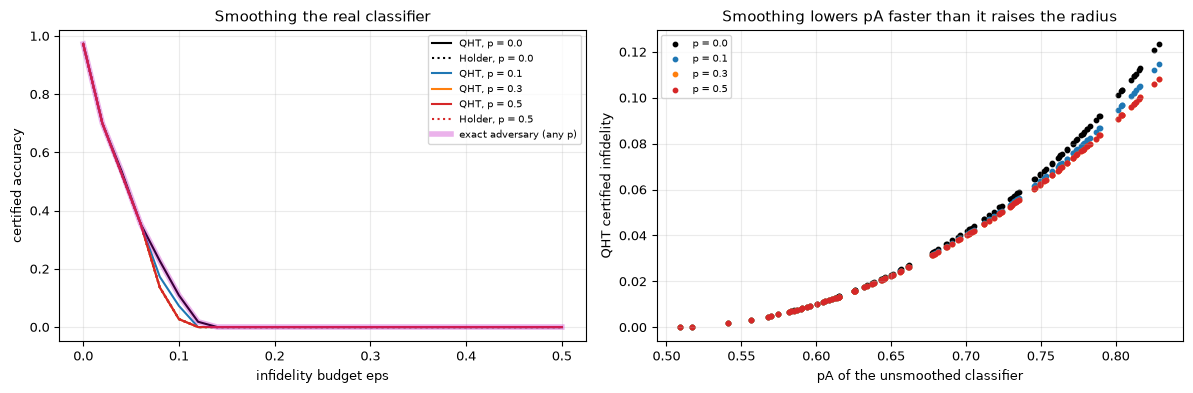

d =  2: exact QHT trace-distance radius at fixed pA' in (0.7, 0.8, 0.9) for p = 0, 0.1, 0.3, 0.5:
[[0.204 0.228 0.299 0.447]
 [0.316 0.357 0.492 0.822]
 [0.447 0.521 0.912 1.   ]]   non-decreasing in p: True


d = 64: exact QHT trace-distance radius at fixed pA' in (0.7, 0.8, 0.9) for p = 0, 0.1, 0.3, 0.5:
[[0.204 0.224 0.286 0.4  ]
 [0.316 0.343 0.429 0.6  ]
 [0.447 0.481 0.582 0.8  ]]   non-decreasing in p: True

For this classifier smoothing does NOT help: the exact adversarial radius is unchanged and the smoothed QHT certificate (median eps per p: [0.0432, 0.0417, 0.0413, 0.0413]) never exceeds it (sound: True).


In [19]:
# ---- depolarisation smoothing (Eq. 41-43) applied to the trained 6-qubit classifier ----
# (1) exact effect of E_p on this classifier, asserted against Qiskit:  y0(E_p(sigma)) = (1 - p) y0(sigma) + p / 2   (tr Lambda_0 / 64 = 1/2)
for p_ in (0.1, 0.5):
    for j in range(1):
        p0_dm = Statevector.from_instruction(depolarised_classifier_circuit(X_ev[j], theta_star, p_)).probabilities([0])[0]
        assert abs(p0_dm - ((1 - p_) * y0_ev[j] + p_ / 2)) < 1e-9
print("OK: y0(E_p sigma) = (1-p) y0(sigma) + p/2 on 6 qubits (19-qubit purified circuit of the architecture section, 2 runs)")

rows_s, eps_by_p, hol_by_p = [], {}, {}
t_s = time.time()
for p_ in SMOOTH_P:
    pA_p = (1 - p_) * pA_ev + p_ / 2                                      # class probability of the smoothed classifier on E_p(sigma)
    # QHT (Theorem 1 on E_p(sigma) vs E_p(rho), exact 2x2 reduction in dimension 64) -> largest certified infidelity of the input pair
    eps_p = np.array([1 - F_crit_dep(p_, a_, D) for a_ in pA_p])
    # Holder (Eq. 45): T(rho, sigma) < (2 pA' - 1) / (2 (1 - p))  with T^2 = 1 - F for pure states
    hol_p = np.minimum((2 * pA_p - 1) / (2 * (1 - p_)), 1.0) ** 2
    eps_by_p[p_], hol_by_p[p_] = eps_p, hol_p
    rows_s.append(dict(p=p_, median_pA_after_smoothing=round(float(np.median(pA_p)), 3), median_eps_QHT=round(float(np.median(eps_p)), 4),
                       median_eps_Holder=round(float(np.median(hol_p)), 4), median_eps_exact_adversary=round(float(np.median(eps_opt)), 4),
                       cert_acc_QHT_at_eps_0_02=round(float(np.mean(correct_ev & (eps_p > 0.02))), 3),
                       cert_acc_Holder_at_eps_0_02=round(float(np.mean(correct_ev & (hol_p > 0.02))), 3)))
tab_s = pd.DataFrame(rows_s)
print(f"\nSmoothed classifier (d = 64), {N_EVAL} test states ({time.time() - t_s:.0f}s):")
print(tab_s.to_string(index=False))
# (2) the true robustness of the smoothed classifier is that of the unsmoothed one: Lambda_p = (1-p) Lambda_0 + (p/2) 1  (same decision rule)
sound_s = all(bool(np.all(eps_by_p[p_] <= eps_opt + 1e-6)) for p_ in SMOOTH_P)
sound_h = all(bool(np.all(hol_by_p[p_] <= eps_opt + 1e-6)) for p_ in SMOOTH_P)
print(f"\nboth certificates stay below the exact adversarial radius of the (unchanged) decision rule: QHT {sound_s}, Holder {sound_h}")
print(f"QHT >= Holder for every p and state: {all(bool(np.all(eps_by_p[p_] >= hol_by_p[p_] - 1e-9)) for p_ in SMOOTH_P)}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for p_, colr in zip(SMOOTH_P, ["k", "tab:blue", "tab:orange", "tab:red"]):
    ax[0].plot(EPS_GRID, [np.mean(correct_ev & (eps_by_p[p_] > e)) for e in EPS_GRID], color=colr, label=f"QHT, p = {p_}")
    ax[0].plot(EPS_GRID, [np.mean(correct_ev & (hol_by_p[p_] > e)) for e in EPS_GRID], color=colr, ls=":", label=f"Holder, p = {p_}" if p_ in (0.0, 0.5) else None)
ax[0].plot(EPS_GRID, rob_opt, "m-", lw=4, alpha=0.3, label="exact adversary (any p)")
ax[0].set_xlabel("infidelity budget eps"); ax[0].set_ylabel("certified accuracy"); ax[0].set_title("Smoothing the real classifier"); ax[0].legend(fontsize=7)
for p_, colr in zip(SMOOTH_P, ["k", "tab:blue", "tab:orange", "tab:red"]):
    ax[1].scatter(pA_ev, eps_by_p[p_], s=10, color=colr, label=f"p = {p_}")
ax[1].set_xlabel("pA of the unsmoothed classifier"); ax[1].set_ylabel("QHT certified infidelity"); ax[1].set_title("Smoothing lowers pA faster than it raises the radius"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# (3) the effect the paper describes: at FIXED smoothed confidence pA' the radius grows with p (Fig. 5), checked on the exact curve in d = 2 and d = 64
mono = {}
for d_ in (2, D):
    vals = np.array([[np.sqrt(1 - F_crit_dep(p_, pa_, d_)) for p_ in (0.0, 0.1, 0.3, 0.5)] for pa_ in (0.7, 0.8, 0.9)])
    mono[d_] = bool(np.all(np.diff(vals, axis=1) >= -1e-9))
    print(f"d = {d_:2d}: exact QHT trace-distance radius at fixed pA' in (0.7, 0.8, 0.9) for p = 0, 0.1, 0.3, 0.5:\n{np.round(vals, 3)}   non-decreasing in p: {mono[d_]}")
add_claim("F5c", "Fig. 5 / text", "depolarisation smoothing enlarges the QHT radius at fixed class probability pA", "enhances the bound",
          f"radius non-decreasing in p at fixed pA' (d=2: {mono[2]}, d=64: {mono[D]})", "reproduced" if all(mono.values()) else "not reached")
print(f"\nFor this classifier smoothing does NOT help: the exact adversarial radius is unchanged and the smoothed QHT certificate (median eps per p:"
      f" {[float(r['median_eps_QHT']) for r in rows_s]}) never exceeds it (sound: {sound_s}).")

## 12. Paper versus this notebook: one verdict per claim

Verdict rules (the factory rules): "reproduced" when a printed number is within 0.02 (absolute) or an identity holds to numerical
precision or a "guaranteed" statement has zero violations; "not reached" when it fails; "cannot be checked" when the PDF alone
does not allow a test. The paper reports no accuracy and no runtime, so there is nothing of that kind to compare.

In [20]:
# ---- side-by-side comparison: the paper's claims versus this notebook, one verdict per claim ----
# claims that cannot be tested from the PDF alone
add_claim("X1", "Suppl. Notes 1-6", "proofs of Lemma 1, Corollary 1 (convex-hull argument), Eq. (43) and Protocol 1 details", "proved in the supplement",
          "the supplement is not part of the PDF; the statements were instead tested numerically (rows above)", "cannot be checked")
add_claim("X2", "Discussion", "tightness for pA + pB < 1 (multi-class with a weak runner-up) is open", "open question", "not addressed (the multi-class runs of Theorem 1 only test soundness)", "cannot be checked")
add_claim("X3", "Intro / Fig. 1", "quantum classifiers are as vulnerable to adversarial perturbations as classical ones", "cited from refs. 11-14",
          "the trained 6-qubit classifier is flipped by an infidelity of about %.3f (median), see the attack section" % float(np.median(eps_att_c)), "cannot be checked")

claims_df = pd.DataFrame(CLAIMS)
pd.set_option("display.max_colwidth", 95, "display.width", 250)
print(claims_df[["id", "where", "claim", "paper", "notebook", "verdict"]].to_string(index=False))
counts = claims_df.verdict.value_counts()
print("\nverdict counts:", counts.to_dict(), f"| total claims {len(claims_df)}")
print(f"\nnotebook wall-clock so far: {(time.time() - t_notebook_start) / 60:.1f} minutes (FAST_MODE = {FAST_MODE})")

 id            where                                                                                                   claim                        paper                                                                                                   notebook           verdict
 A1           Eq. 31                                      optimal type-II error beta* for theta0=pi/3, phi0=pi/6, alpha0=0.1                        ~0.44                                                                                                     0.4402        reproduced
 A2           Eq. 33                                                             maximal certified angle theta0 for pA = 0.9                    ~0.93 rad                                                                                0.9273 (SDP boundary 0.930)        reproduced
 A3           Eq. 34                                                             classifier angle theta = 2 arccos(sqrt 0.9)                   ~0.644 rad          

## 13. Reading the paper critically

**What held up.** Every number the paper prints is reproduced: `beta* = 0.4402` (Eq. 31, with the printed eigenvector of Eq. 30 being
exactly the Helstrom projector), the certified angle `0.9273 rad` (Eq. 33), `theta = 0.6435` (Eq. 34), the orderings of Fig. 2 on
100 % of the `(pA, pB)` grid, the noise bounds (38) and (40) (identical to a bisection on the real Qiskit-Aer channel to 1e-13), and
Eq. (43), whose two branches and switching point match the exact semidefinite-programme radius to numerical precision once the
garbled PDF text is parsed with `1/(1-p)` *inside* the outer square root. Theorem 1 had zero violations in 1992 certified states
(400 random classifiers, dimensions 2-8, 2-4 outcomes, pure and mixed states), the worst-case classifier of Theorem 2 flipped all 251
violating pairs and none of the 149 robust ones, Lemma 1 matched on 20,150 draws, and the fidelity bound of Theorem 3 had zero
violations on 1276 mixed pairs.

**What did not hold as printed.**

1. *The example classifier does not flip `rho`.* The text after Eq. (34) says that for `theta = 0.644`, `phi = pi/2` one has
   `A(rho) != A(sigma)`. Computed directly, `y_+(sigma) = 0.900` and `y_+(rho) = 0.830`: both states get the class `+`. The theory is
   fine (`beta* = 0.4402 < 1/2` guarantees that *some* 90 %-confident classifier flips `rho`): the flip happens for azimuths
   `phi` between `0.95 pi` and `1.39 pi` and is largest at `phi = 7 pi/6`, where `y_+(rho) = 0.4402 = beta*` exactly, so the printed `pi/2`
   is probably a typo. (Verdict A4: "not reached"; A5, the existence of the flipping classifier, is reproduced.)
2. *"Tight" for the noise bounds is only half true.* Eqs. (38)/(40) are sufficient and exactly right as consequences of Theorem 3, but
   Theorem 3's necessity concerns the worst case over *all* states at that fidelity. For the specific output state `N_gamma(sigma)` the exact
   condition (10) tolerates up to 0.52 more noise than the bound (verdict F4c: "not reached" for necessity).
3. *Corollary 1 is very loose.* With a pure benign state and mixed adversaries, the exact radius (smallest exit distance over sampled
   directions) coincides with the Holder radius `(pA - pB)/2` in dimension 2, the pure-state QHT radius `r_Q` is *too large* for mixed
   adversaries (0.447 versus the exact 0.400 at `pA = 0.9`), and the convex-hull radius of Eq. (21) is far below both (0.099 for the
   literal reading of `delta`, 0.047 for `delta = r_Q`). The paper says this ordering (`r_Q > r_H > r~_Q`) and it holds, but it also means
   that for trace distance the Holder bound is the better tool against mixed adversaries; the QHT advantage lives in the fidelity.
4. *Eq. (21) and Eq. (43) are hard to read* in the published text (the PDF text loses the square roots). Both readings of `delta` pass the soundness test; Eq. (43) is
   right as reconstructed here.

**What "optimal" means.** The certificate is optimal over *all classifiers sharing the same `(pA, pB)`*, not for the classifier in hand.
For the random classifiers of Theorem 1 the first flip happened at about 2.25 times the last certified perturbation strength
(median over 49 paths), i.e. the certificate is conservative for a generic measurement. For a **projective** measurement of a
large Hilbert space such as the trained classifier of Part B, the worst-case classifier of Theorem 2 *is* the classifier (a rank-32 projector in
64 dimensions leaves enough room), and the certificate is exact: the exact optimal adversary (Lagrange dual) and the gradient attack
(complex or real amplitudes) flip the prediction at the QHT infidelity for all 110 test states (largest deviation 9e-13 and 0.0000), 0 of 220 attacks succeeded
inside the certified region, and the Holder bound (median 0.96 of the exact radius) is close but never tight. Random orthogonal
perturbations at 1.5 times the certified radius flip the prediction in 0 % of the draws: the certified radius is about worst-case geometry,
not about typical noise.

**Does it help a security user?** Honest numbers on the digit task: the trained 6-qubit model is as accurate as the classical baselines
(0.987 +- 0.009 versus 0.987-0.991 over 5 seeds), but it is not very confident (median `pA = 0.70`), so the median certified infidelity is
only 0.043 (an l2 distance of about 0.21 between unit vectors, roughly a fifth of the vector length). Certified accuracy at `eps = 0.02`, 0.06, 0.10: QHT 0.70, 0.36, 0.11;
Holder 0.70, 0.36, 0.03; classical randomised smoothing on the same unit vectors 0.82, 0.39, 0.09. The quantum certificate is therefore not
better than a well-tuned classical one here; its attraction is that it needs no noise training, no extra samples to *create*
randomness and covers every complex or mixed perturbation, at the price of estimating `pA` by repeated execution (with
`N = 2000` and `alpha = 0.001` the Hoeffding penalty is 0.04 of `pA`, which cuts certified accuracy at `eps = 0.02` from 0.70 to 0.57). Two caveats a security reader should keep in mind:
the guarantee is about perturbations of the *quantum state*; an attacker who edits network features or pixels
under physical constraints (non-negative, quantised) is weaker than the state-space adversary, so the certificate may be pessimistic, but any
mismatch between the classical edit and the encoded state (here amplitude encoding turns an l2 edit into infidelity) must be modelled by the user; and
depolarisation smoothing, which enlarges the radius at *fixed* confidence (Fig. 5, reproduced in dimension 2 and 64), does not help this
classifier: smoothing leaves the decision rule, hence the exact radius, unchanged and lowers `pA`, so the smoothed certificate
(median 0.043, 0.042, 0.041, 0.041 for `p = 0, 0.1, 0.3, 0.5`) never exceeds the unsmoothed one. Protocol 2 produced 0 false certifications among 42 certified outcomes in 6 noise settings, but also certified (almost) nothing once
the infidelity reached about 0.07: for noise this strong the guarantee is vacuous at this confidence even though at most one of the 40 predictions changed.

**Limits of this reproduction.** The supplement (proofs of Lemma 1, Corollary 1, Eq. 43, Protocol 1) is not in the PDF, so those
statements are tested numerically, not re-proved; the open question of tightness for `pA + pB < 1` is not addressed; the digit
experiment, the classical baseline and the attacks are our additions and have no counterpart in the paper; the classical-versus-quantum
comparison uses one dataset, one noise-trained logistic-regression base classifier and a map between l2 radius and fidelity that is exact only for unit vectors.

## 14. Exercises

1. **Another task.** Set `DIGIT_PAIR = (4, 9)` (or `(1, 7)`, an easy pair) and re-run. How do the distribution of `pA`, the certified
   accuracy and the gap between the certificate and the exact adversary change? Which pairs give larger certified radii, and why?
2. **Weaker runner-up.** Replace the single-qubit read-out by a read-out of two qubits (four classes, so `pB < 1 - pA` is possible).
   Use Theorem 1 with a measured `pB` (two terms `beta*_{1-pA} + beta*_{pB}`) and compare with the closed form of Eq. (17). Is
   the certificate still tight for the trained model? (The paper leaves tightness for `pA + pB < 1` open.)
3. **Depth.** Change `REPS` to 1 and to 6. Plot the median certified `eps` against the test accuracy. Does a more expressive ansatz
   buy confidence (larger `pA`) or only accuracy?
4. **Another smoothing channel.** Replace the depolarising channel of Section 6 by amplitude damping on a single qubit. Derive (or find
   numerically with `beta_star`) the exact radius at fixed `pA'` and compare with the depolarising curve of Fig. 5. Which channel
   enlarges the radius more per unit of lost confidence?
5. **Mixed adversaries.** In Section 4 the exact radius for a pure benign state and a mixed adversary equals the Holder radius
   in dimension 2. Construct, with the Helstrom operator, the mixed state `rho = r|sigma><sigma| + (1 - r)|w><w|` that attains it, and
   explain why the pure-state radius `r_Q` of Eq. (16) cannot hold for it.
6. **Shots.** Reduce `SHOTS_PROTOCOL` to 100 and 500. How does the abstention rate of Protocol 1 and the loss in certified accuracy
   grow, and how many executions per image does a certified radius of `eps = 0.05` need for `pA = 0.7`?